# 1. mPower dataset: completed characterization and distributions

**Evidence snapshot: 2026-11-16.** This notebook contains saved aggregate results from the completed full-data analysis,
rather than the original 120-recording extraction pilot. It runs from a Git clone with no mPower credentials or audio.
Every code cell only reads reviewed aggregates under `docs/results`; none launches preprocessing or training.

Read in order: source/data dictionary → diagnosis/age → repeated visits → duration/QC → acoustic features → cohort/split audit.
Notebook 2 covers the later supervised experiments. The original private analysis template is retained separately under
`notebooks/private/`; rerunning it requires authorized HPC storage.

These data were contributed by users of the Parkinson mPower mobile application as part of the mPower study developed
by Sage Bionetworks and described in Synapse [doi:10.7303/syn4993293](https://doi.org/10.7303/syn4993293).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/mpower_preprocessing.yaml').exists())
RESULTS = REPO/'docs/results'
pd.set_option('display.max_colwidth', 120)
def table(relative):
    data = pd.read_csv(RESULTS/relative)
    with pd.option_context('display.max_rows', len(data)+1, 'display.max_columns', None):
        display(data)
    return data
def report(relative):
    display(Markdown('```json\n'+json.dumps(json.loads((RESULTS/relative).read_text()),indent=2)+'\n```'))
def figure(relative):
    display(Image(filename=str(RESULTS/relative)))

## What succeeded and what failed

Source census: **65,022 recordings / 5,826 participants**. The repaired full extraction succeeded on **64,973** recordings;
**49** malformed/empty source objects remained undecodable. The earlier worker/Numba failures were implementation failures,
repaired before this report; they do not invalidate the source census or age distributions. The source-file audit found
the remaining 49 local objects matched Synapse sizes/checksums. They were retained as failures, never filled with fabricated audio.

Diagnosis remains self-report of professional diagnosis, not an independent clinical assessment. The cleaned participant
classification has **970 PD, 3,890 control, 864 unknown, 102 conflicting**. Unknown/conflicting people are excluded from binary modeling.
Medication timing is never used as a diagnosis proxy. Full descriptive summaries precede supervised splitting and must not
be mistaken for estimates from an independent prospective cohort.

## Storage tree and the files that encode the data

```text
projects/
  pd_env/                              GitHub: portable code and aggregate reports
    notebooks/                         these two executed reports
    notebooks/private/                 private-analysis source template, output-free
    configs/                           preprocessing, native model and training settings
    scripts/; src/; tests/              executable procedures and synthetic verification
    docs/results/                      aggregate CSV/JSON/figures used in these notebooks
  pd_data/                             approved HPC data; not included in a Git clone
    mpower/                            MPOWER_DATA_ROOT
      voice_activity/Voice_Activity.csv 65,022 source observations; one recording per row
      voice_activity/metadata_parts/   download-query shards, not extra observations
      voice_activity/audio/            encoded sustained-phonation files; inspect codec
      demographics/Demographics.csv    separately linked baseline survey export
      synapse_cache/                   cached source objects; not a second dataset
    mpower_phase1/                     MPOWER_OUTPUT_ROOT
      processed/                       linked manifests, QC, acoustic features, A/B/C splits
      eda/{tables,figures,diagnostics}/ completed private characterization evidence
      archive/                         older/pilot snapshots; not current denominators
    mpower_benchmarks/                  MPOWER_BENCHMARK_ROOT
      models/; activations/            model assets and private derived embeddings
      protocol_experiments/            immutable development manifests and frozen runs
      adaptation_20261114/             historical training runs
      controlled_ast/; hear_protocol/  corrected controlled runs
      literature_methods/              LP-FT/LoRA/SupCon/TabICL experiments
      acoustic_xgboost/                GPU search database, fitted trees, private predictions
    assistant_samples/                 private 100-recording training-only handoff
```

| File/field | Meaning and handling |
|---|---|
| `Voice_Activity.csv` | Original recording table, Synapse `syn5511444`; use the consolidated export once. |
| `recordId` / `healthCode` | Recording and participant linkage keys; healthCode is a pseudonym, not anonymization. |
| `audio_audio.m4a` | Synapse file-handle field pointing to sustained phonation. It is not numeric audio features. |
| `audio_countdown.m4a` | Separate countdown handle; not the intended phonation signal. |
| `audio_path` | Local source object path added by the downloader; resolve from approved storage. |
| `createdOn`, `medTimepoint` | Acquisition time and self-reported medication timing; not clinical ON/OFF adjudication. |
| `Demographics.csv` | Baseline table `syn5511429`: age, gender, diagnosis and other self-reported covariates. |
| `participant_manifest.parquet` | One cleaned participant row with conservative diagnosis/conflict and demographic linkage. |
| `recording_manifest.parquet` | One source recording row with participant link, task, dates, label and path. |
| `full_audio_quality_metrics.parquet` | Duration/native-format/QC/hash/status per recording, including failed rows. |
| `full_acoustic_features.parquet` | 184 numeric acoustic columns plus processing status; undefined measurements are missing. |
| `feature_dictionary.csv` | Feature names, units and definitions; safe schema dictionary displayed below. |
| `cohort_{A,B,C}/` | Private manifests/splits for labeled technical, pitch sensitivity and matched cohorts. |
| `development_manifest.parquet` | Later immutable train/validation snapshot: source hashes, waveform links, component and initial-visit flags. |
| `.m4a`, `.tmp`, extensionless files | The original filename suffix may not identify the actual media codec. Probe/decode content. |
| `.npy`, `.npz`, `.pt`, `.joblib`, prediction CSVs | Derived waveforms, embeddings, weights, estimators and individual predictions; private. |

The historical filesystem inventory includes cache/download artifacts and therefore is not a count of unique recordings.

In [2]:
report('dataset_characterization/table_inventory.json')
report('dataset_characterization/discovery_summary.json')

```json
{
  "canonical_tables": [
    {
      "table": "voice_activity/Voice_Activity.csv",
      "rows": 65022,
      "columns": 9,
      "duplicate_rows": 0
    }
  ],
  "total_audited_tables": 524,
  "cached_query_and_download_shards": 523,
  "interpretation": "Cache tables and download shards overlap the canonical export; never add their rows as observations."
}
```

```json
{
  "files": 131091,
  "total_bytes": 87251529380,
  "file_types": {
    "": 65545,
    ".tmp": 65022,
    ".csv": 524
  },
  "metadata_tables": 524,
  "recordings": 65022,
  "participants": 5826,
  "missing_audio": 0,
  "duplicate_recording_ids": 0,
  "recording_diagnoses": {
    "pd": 39388,
    "control": 22782,
    "unknown": 2174,
    "conflicting": 678
  },
  "participant_diagnoses": {
    "control": 3890,
    "pd": 970,
    "unknown": 864,
    "conflicting": 102
  },
  "recordings_per_participant": {
    "n": 5826,
    "missing": 0,
    "mean": 11.16065911431514,
    "sd": 39.2635326947092,
    "min": 1.0,
    "max": 522.0,
    "q1": 1.0,
    "q5": 1.0,
    "q25": 1.0,
    "q50": 3.0,
    "q75": 6.0,
    "q95": 35.0,
    "q99": 211.75
  },
  "longitudinal_participants": 4299,
  "single_recording_participants": 1527,
  "top_1_percent_recording_share": 0.3041893512964843,
  "followup_days": {
    "n": 5826,
    "missing": 0,
    "mean": 9.35637361174683,
    "sd": 26.17480606760536,
    "min": 0.0,
    "max": 183.92024305555555,
    "q1": 0.0,
    "q5": 0.0,
    "q25": 0.0,
    "q50": 0.002170138888888889,
    "q75": 3.6393750000000002,
    "q95": 58.426440972222224,
    "q99": 152.05791956018518
  },
  "relationships": {
    "voice_to_participant": "many-to-one, healthCode grouping; no external demographic or clinical join performed",
    "shards": "audited against consolidated source, never concatenated",
    "countdown": "handles inventoried; no local countdown mapping assumed; downloader retrieves only sustained phonation",
    "demographics": "syn5511429 baseline linked by healthCode; one-to-one participants / many-to-one recordings; duplicates fail closed; no temporal clinical-survey matching"
  },
  "source_participant_diagnoses": {
    "control": 3992,
    "pd": 970,
    "unknown": 864
  },
  "source_recording_diagnoses": {
    "pd": 39388,
    "control": 23460,
    "unknown": 2174
  },
  "demographics_matched_participants": 5044,
  "demographics_unmatched_participants": 782,
  "demographics_matched_recordings": 63255,
  "label_conflict_participants": 102,
  "demographics_table": "syn5511429",
  "diagnosis_definition": "Participant-reported professional diagnosis; not independently clinically adjudicated",
  "historical_blockers_at_metadata_audit": [
    "Full-audio processing, near-duplicate review and label/QC sensitivity remain pending"
  ],
  "current_scope_note": "Full extraction completed: 64973/65022; historical pilot/runtime notes are superseded."
}
```

## Diagnosis availability and demographic coverage

Recording-level PD prevalence is much higher than participant-level PD prevalence because PD volunteers contribute more visits.
Use the participant denominator for screening performance and demographic comparisons. Baseline demographics matched 5,044
participants / 63,255 recordings; unmatched participants and missing fields remain explicit.

,diagnosis,participants,recordings
0,conflicting,102,678
1,control,3890,22782
2,pd,970,39388
3,unknown,864,2174


,diagnosis,age_available,sex_available,longitudinal
0,conflicting,101,102,75
1,control,3868,3878,3003
2,pd,966,968,866
3,unknown,73,72,355


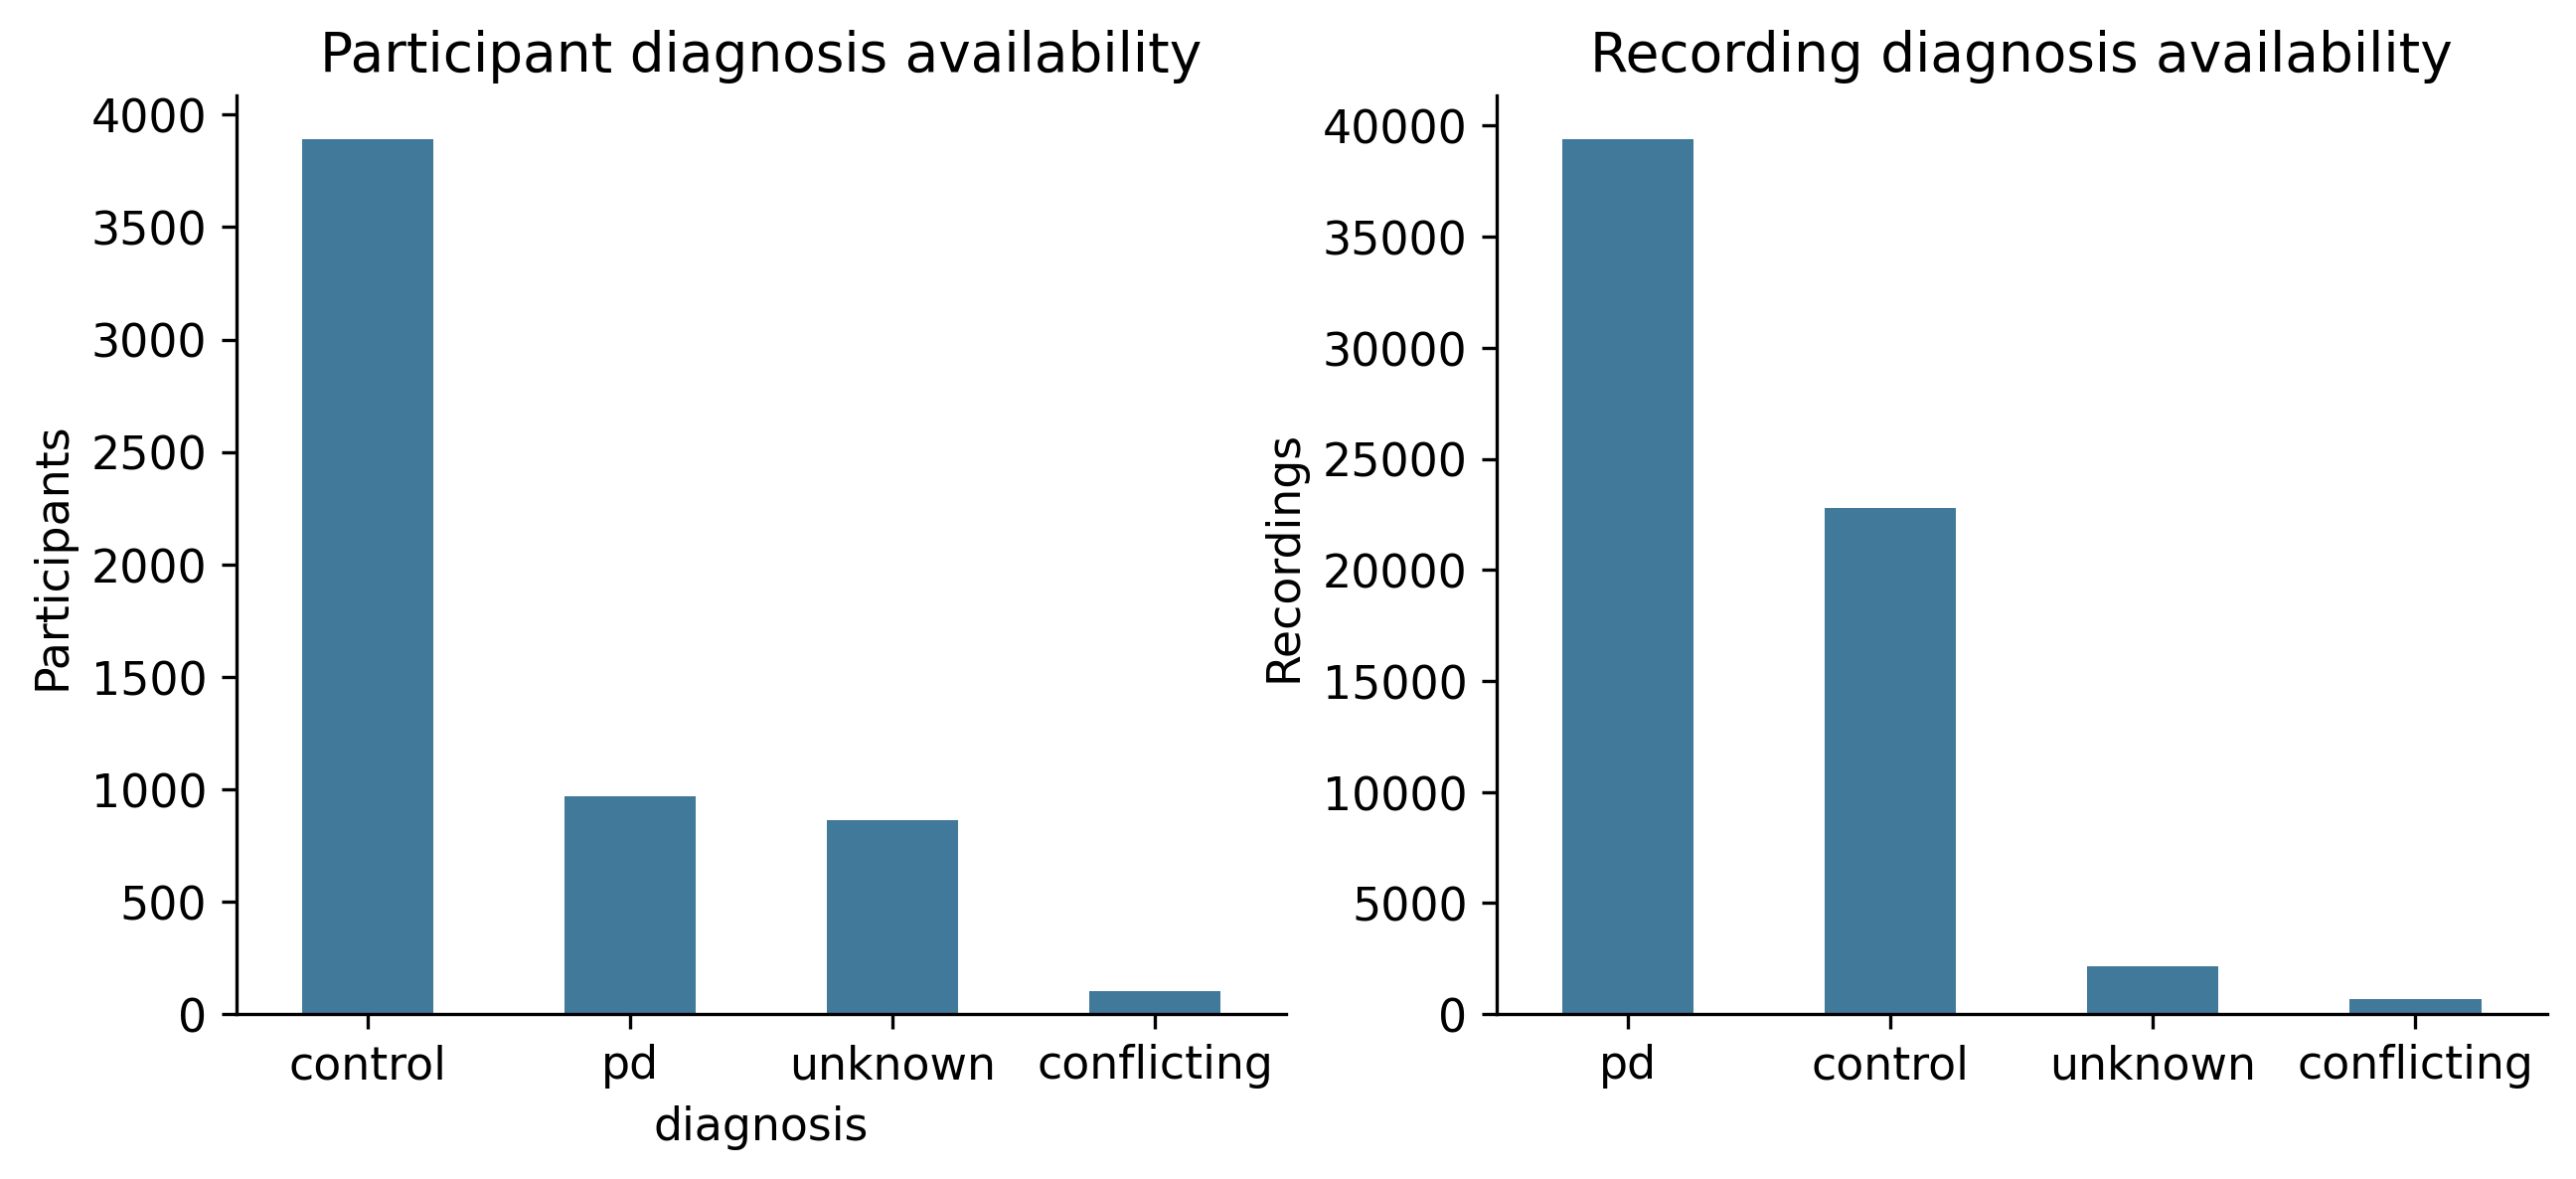

In [3]:
table('dataset_characterization/tables/cohort_characteristics.csv')
table('dataset_characterization/tables/demographic_coverage.csv')
figure('dataset_characterization/figures/diagnosis_availability.png')

## Age, sex and confounding

The completed participant summaries show median age **61 in PD versus 29 in controls**. Age and diagnosis are strongly entangled;
this is a major explanation for the high age-only predictive baseline in Notebook 2. Reporting apparent voice separation
without age/device controls would be misleading. Sex/gender is self-reported; missing/conflicting entries are retained.
The table includes both participant and recording summaries: compare the `level` column before interpreting a row.
The binned age table includes an explicit `nan` category for missing values.

,level,diagnosis,n,age_missing,sex_missing,age_n,age_mean,age_sd,age_min,age_max,age_q1,age_q5,age_q25,age_q50,age_q75,age_q95,age_q99
0,participant,conflicting,102,1,0,101,33.663366,16.118485,18.0,90.0,18.00,18.0,21.0,28.0,44.0,67.00,74.00
1,participant,control,3890,22,12,3868,32.696225,13.084437,18.0,86.0,18.00,18.0,23.0,29.0,39.0,61.00,72.33
2,participant,pd,970,4,2,966,60.336439,11.039714,18.0,90.0,27.65,41.0,54.0,61.0,68.0,75.75,83.00
3,participant,unknown,864,791,792,73,33.287671,14.060859,18.0,74.0,18.00,19.0,24.0,29.0,43.0,61.00,72.56
4,recording,conflicting,678,3,0,675,46.863704,18.695493,18.0,90.0,18.00,18.0,27.0,51.0,63.0,72.00,74.00
5,recording,control,22782,119,24,22663,40.582712,17.461498,18.0,86.0,18.00,19.0,26.0,36.0,54.0,73.00,77.00
6,recording,pd,39388,45,6,39343,63.842742,7.894506,18.0,90.0,41.00,50.0,60.0,65.0,69.0,75.00,78.00
7,recording,unknown,2174,1797,1798,377,43.740053,21.311802,18.0,74.0,18.00,19.8,24.0,33.0,72.0,74.00,74.00


```json
{
  "participant_age_mean_difference": 27.640213483891827,
  "participant_age_median_difference": 32.0,
  "age_smd": 2.28331029843989,
  "gender_proportions": {
    "Female": {
      "control": 0.18978855079938112,
      "pd": 0.34917355371900827
    },
    "Male": {
      "control": 0.8102114492006188,
      "pd": 0.6508264462809917
    }
  },
  "definition": "baseline survey age and reported gender; primary labels exclude contradictions",
  "pd_participants_with_age": 966,
  "control_participants_with_age": 3868
}
```

,diagnosis,age_band,participants
0,conflicting,"(0.0, 18.0]",13
1,conflicting,"(18.0, 30.0]",46
2,conflicting,"(30.0, 40.0]",12
3,conflicting,"(40.0, 50.0]",13
4,conflicting,"(50.0, 60.0]",9
5,conflicting,"(60.0, 70.0]",4
6,conflicting,"(70.0, 80.0]",3
7,conflicting,"(80.0, 90.0]",1
8,conflicting,NaN,1
9,control,"(0.0, 18.0]",264


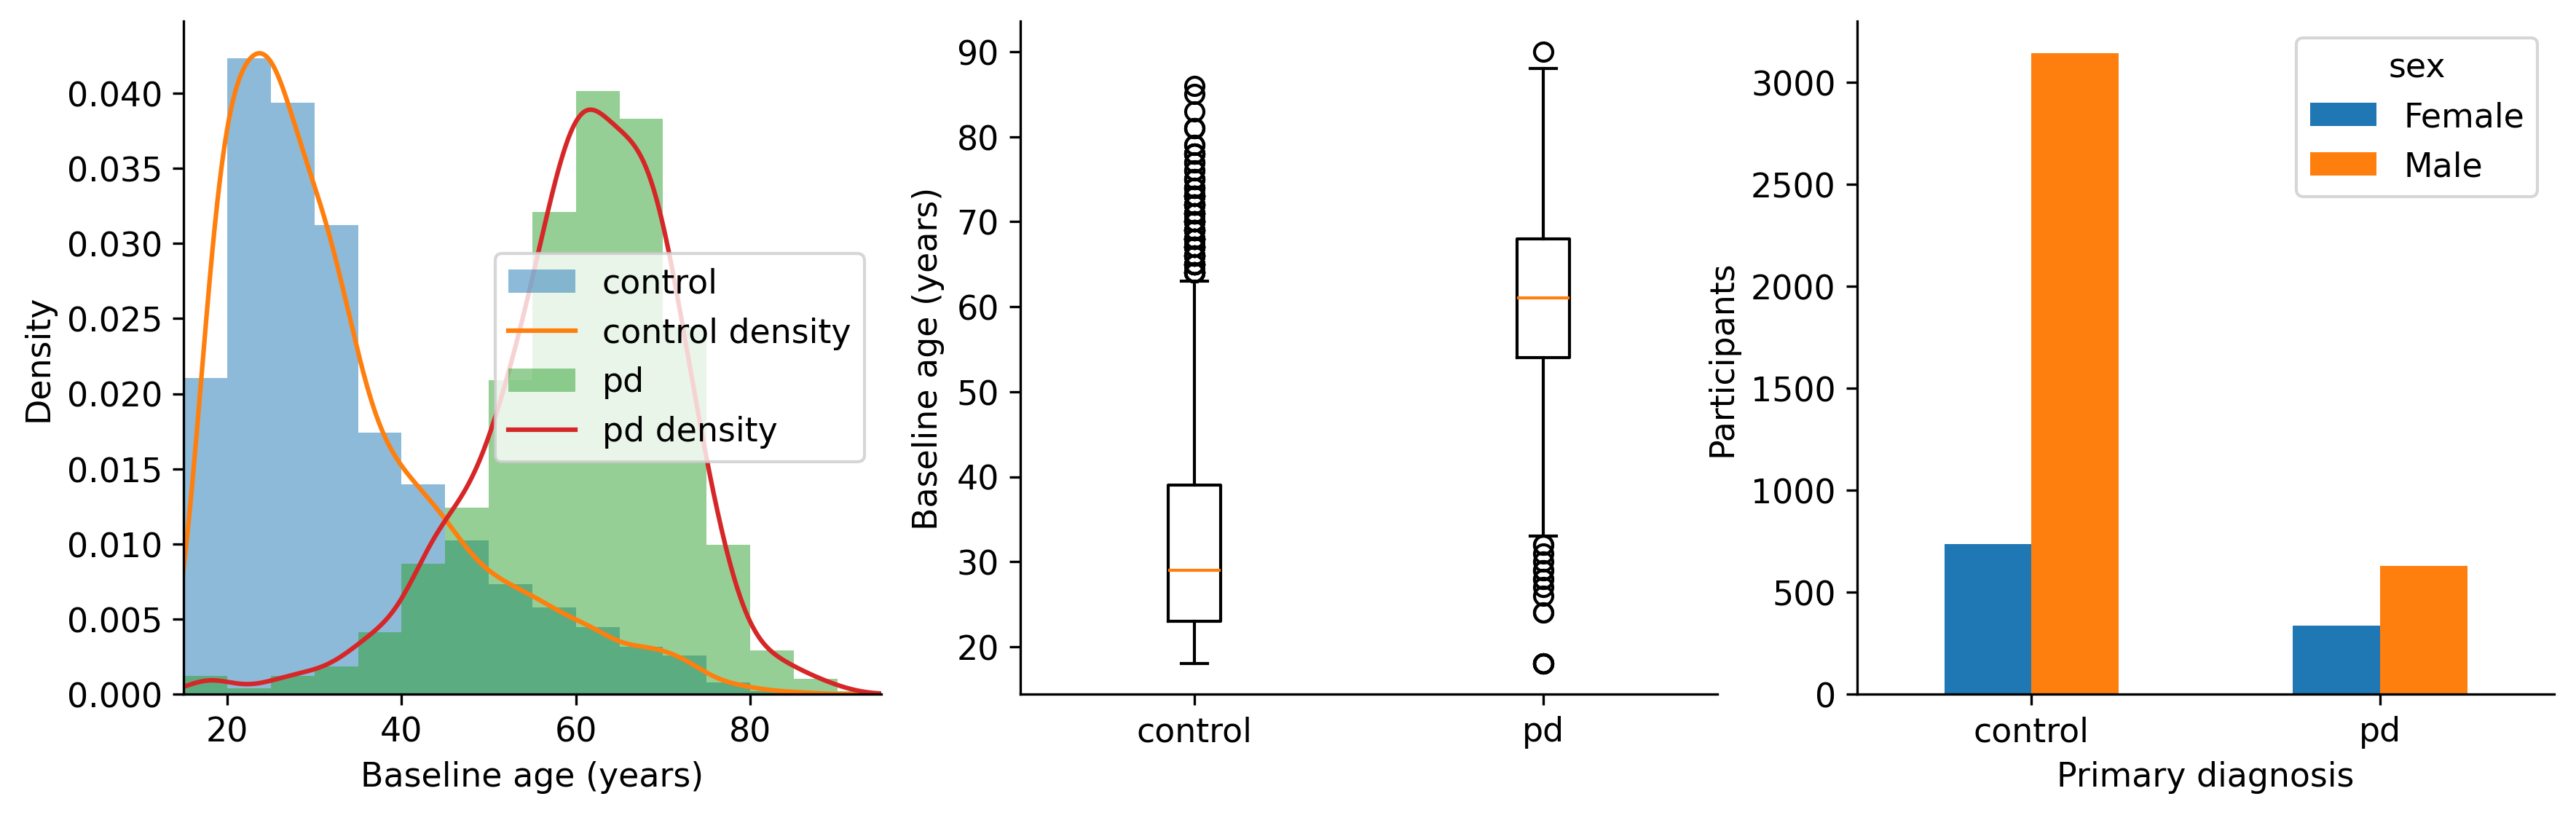

In [4]:
table('dataset_characterization/tables/demographics_by_diagnosis.csv')
report('dataset_characterization/demographic_imbalance.json')
table('dataset_characterization/tables/participant_age_bins.csv')
figure('dataset_characterization/figures/demographic_distributions.png')

## Repeated visits, follow-up and medication

**4,299** participants contributed repeated recordings. Median visits/person is **3**, maximum **522**;
the most active **1% contributed 30.4%** of all recordings. Treating rows as independent people would over-weight these volunteers
and leak participant identity if visits were split independently. Later training either gives each person's visits total weight one
or samples one visit/person/epoch. Validation uses one canonical initial eligible visit/person.

Medication groups are descriptive. A report of before/after medication is not proof of a verified pharmacological ON/OFF pair.
Baseline survey age can precede recordings; no longitudinal clinical severity trajectory is inferred.

,diagnosis,participants,recordings,mean_recordings,median_recordings,median_followup_days,longitudinal
0,conflicting,102,678,6.647059,3.0,0.007378,75
1,control,3890,22782,5.856555,3.0,0.001626,3003
2,pd,970,39388,40.606186,8.0,10.360799,866
3,unknown,864,2174,2.516204,1.0,0.000000,355


,diagnosis,visit_band,participants
0,conflicting,"(0.0, 1.0]",27
1,conflicting,"(1.0, 2.0]",8
2,conflicting,"(10.0, 25.0]",7
3,conflicting,"(2.0, 5.0]",41
4,conflicting,"(25.0, 50.0]",2
5,conflicting,"(5.0, 10.0]",14
6,conflicting,"(50.0, 100.0]",3
7,control,"(0.0, 1.0]",887
8,control,"(1.0, 2.0]",335
9,control,"(10.0, 25.0]",246


,diagnosis,medication,recordings
0,conflicting,Another time,122
1,conflicting,I don't take Parkinson medications,397
2,conflicting,Immediately before Parkinson medication,92
3,conflicting,Just after Parkinson medication (at your best),60
4,conflicting,NaN,7
5,control,Another time,57
6,control,I don't take Parkinson medications,22550
7,control,NaN,175
8,pd,Another time,17638
9,pd,I don't take Parkinson medications,2879


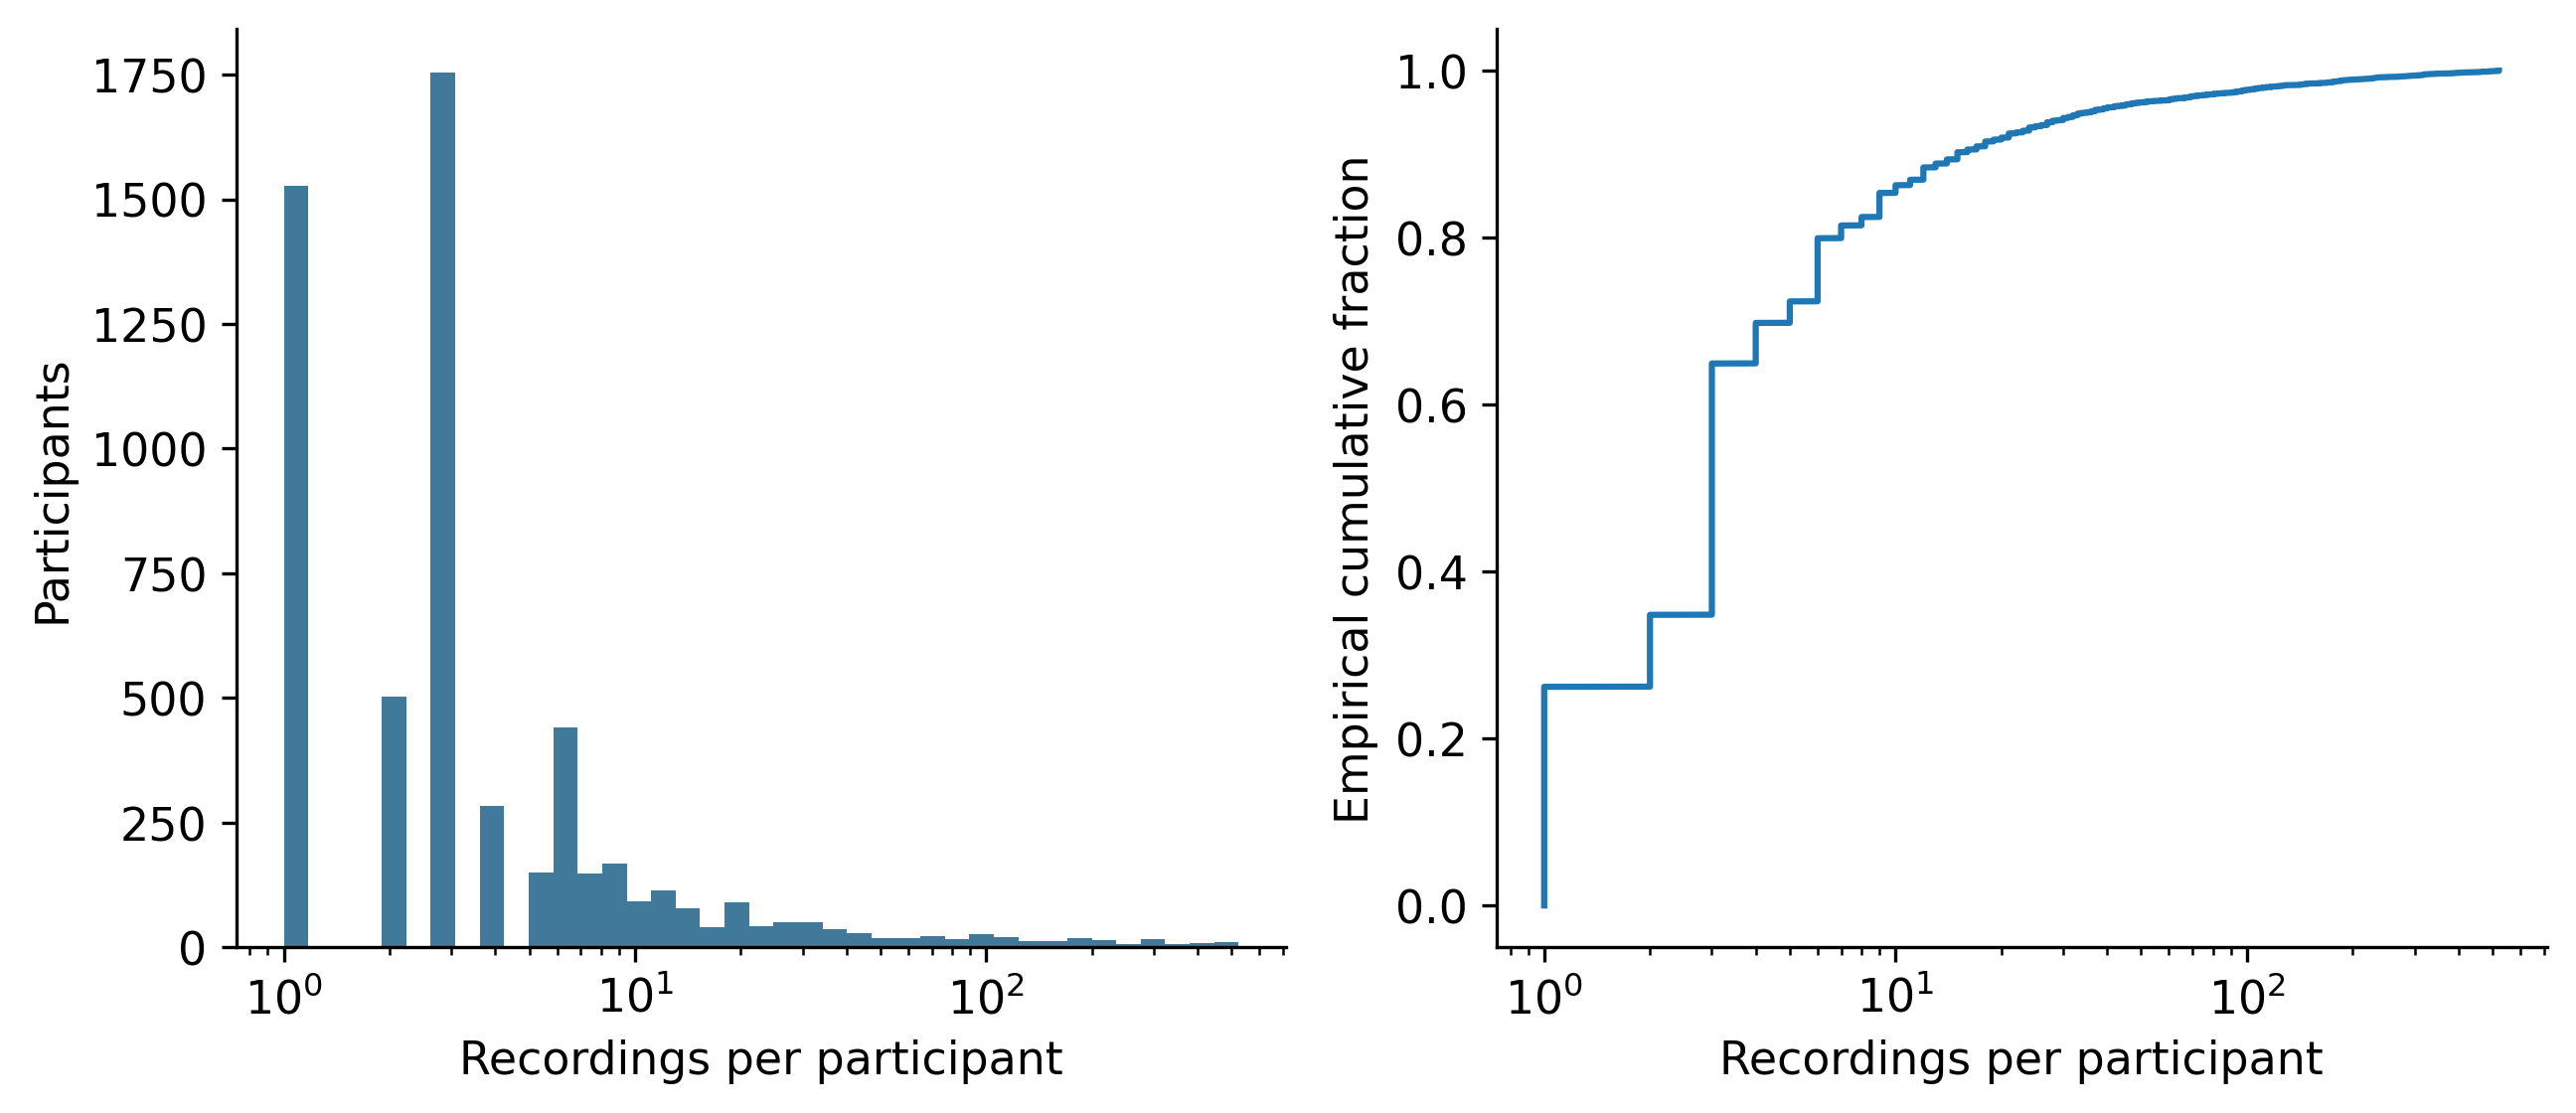

In [5]:
table('dataset_characterization/tables/longitudinal_by_diagnosis.csv')
table('dataset_characterization/tables/participant_visit_bins.csv')
table('dataset_characterization/tables/medication_by_diagnosis.csv')
figure('dataset_characterization/figures/longitudinal_recordings.png')

## Audio length and technical distributions

These summaries use the full extraction scope, before the later encoder first-10-second cap. `n` and `missing` differ by
measurement: use the row-specific denominator. No failed file is treated as a zero-duration recording. Histogram bins describe
decoded/finite lengths; the `nan` bin retains missing durations. The extraction resource guard is 180 seconds.

,metric,n,missing,mean,sd,min,max,q1,q5,q25,q50,q75,q95,q99
0,original_sample_rate,65003,19,4.410000e+04,0.000000,44100.000000,4.410000e+04,4.410000e+04,4.410000e+04,4.410000e+04,4.410000e+04,4.410000e+04,4.410000e+04,4.410000e+04
1,original_channels,65003,19,1.000000e+00,0.000000,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
2,original_bitrate,65003,19,1.068834e+06,45209.847192,706000.000000,1.411000e+06,9.720000e+05,9.990000e+05,1.038000e+06,1.068000e+06,1.098000e+06,1.143000e+06,1.182000e+06
3,container_duration_s,65003,19,1.003330e+01,0.247010,0.090000,1.558000e+01,9.990000e+00,1.001000e+01,1.003000e+01,1.004000e+01,1.005000e+01,1.007000e+01,1.007000e+01
4,file_size_bytes,65022,0,1.340781e+06,68804.417439,28.000000,2.084247e+06,1.219053e+06,1.253719e+06,1.302987e+06,1.340367e+06,1.378290e+06,1.434999e+06,1.483468e+06
5,duration_s,64973,49,1.003773e+01,0.128066,0.743062,1.558069e+01,9.990687e+00,1.000956e+01,1.003019e+01,1.003969e+01,1.004881e+01,1.006825e+01,1.007387e+01
6,analysis_samples,64973,49,1.606037e+05,2049.053713,11889.000000,2.492910e+05,1.598510e+05,1.601530e+05,1.604830e+05,1.606350e+05,1.607810e+05,1.610920e+05,1.611820e+05
7,analysis_sample_rate,64973,49,1.600000e+04,0.000000,16000.000000,1.600000e+04,1.600000e+04,1.600000e+04,1.600000e+04,1.600000e+04,1.600000e+04,1.600000e+04,1.600000e+04
8,peak_amplitude,64973,49,3.886522e-01,0.230303,0.000000,1.222791e+00,5.673702e-02,1.040063e-01,2.253592e-01,3.306545e-01,4.973722e-01,8.725054e-01,1.008733e+00
9,rms_amplitude,64973,49,6.214634e-02,0.043564,0.000000,5.475216e-01,8.529674e-03,1.673464e-02,3.727021e-02,5.624980e-02,7.385781e-02,1.256418e-01,2.717627e-01


,threshold_s,below_threshold,decoded_denominator,scope
0,2,8,64973,full
1,3,10,64973,full
2,5,13,64973,full
3,7,15,64973,full
4,9,18,64973,full


,duration_band,recordings
0,"(0.0, 2.0]",8
1,"(10.0, 11.0]",64032
2,"(11.0, 15.0]",14
3,"(15.0, 20.0]",2
4,"(2.0, 5.0]",5
5,"(5.0, 9.0]",5
6,"(9.0, 10.0]",907
7,NaN,49


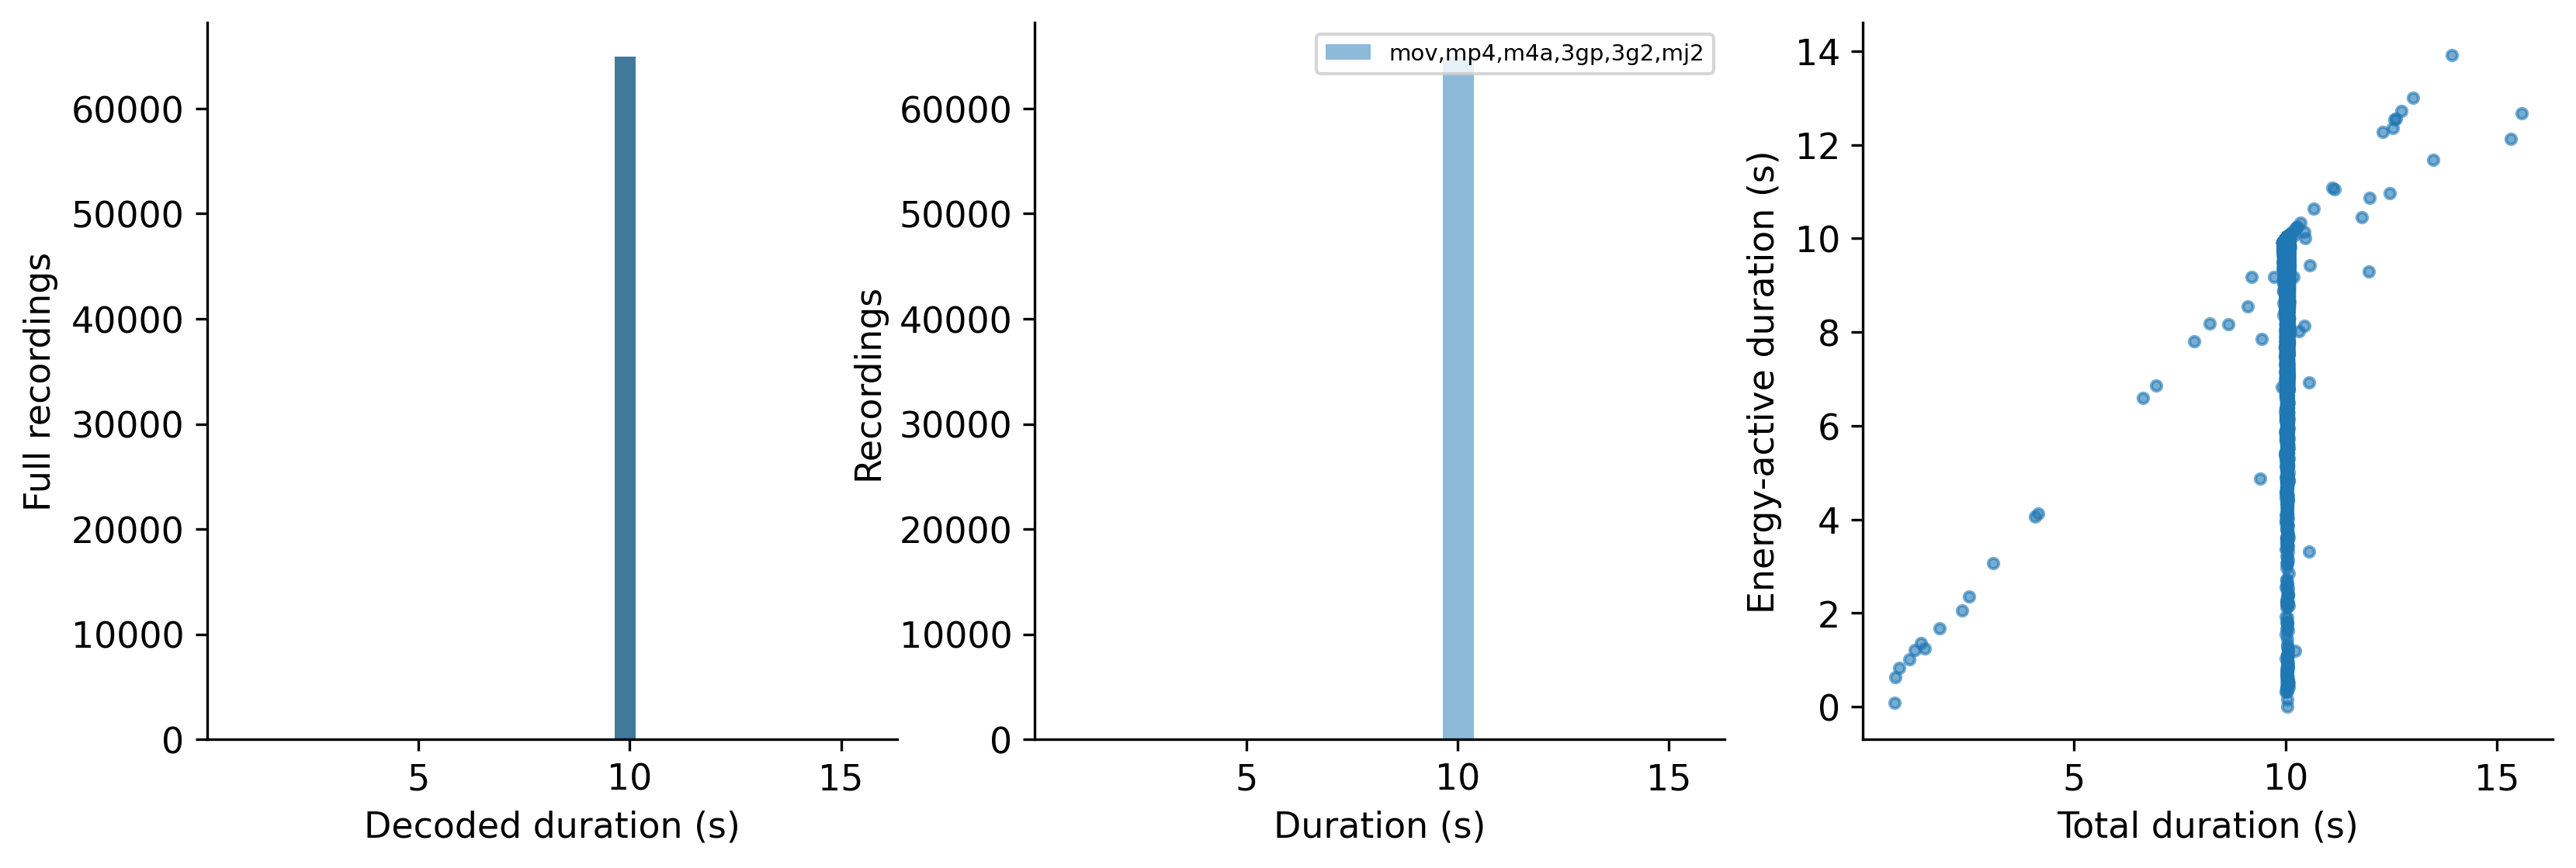

In [6]:
table('dataset_characterization/tables/full_audio_summary.csv')
table('dataset_characterization/tables/duration_threshold_counts.csv')
table('dataset_characterization/tables/duration_bins.csv')
figure('dataset_characterization/figures/audio_duration.png')

## QC warnings, retention and thresholds

Near-silence, clipping, amplitude, energy activity, pitch coverage and decode failures are separately recorded. Aperiodicity,
low amplitude and undefined perturbation values can themselves relate to dysphonia, so they are not blanket primary exclusions.
The historical `estimated_snr_db` is an RMS-percentile energy-range proxy, **not measured environmental SNR**;
its 10 dB flag is unsuitable as a validated noise gate or weight. QC threshold sweeps describe selection sensitivity, not an optimized diagnosis rule.

,diagnosis,criterion,flagged_recordings,recording_denominator,flagged_participants,participant_denominator,scope
0,conflicting,flag_near_silent,0,678,0,102,full
1,conflicting,flag_low_amplitude,0,678,0,102,full
2,conflicting,flag_short,0,678,0,102,full
3,conflicting,flag_short_activity,0,678,0,102,full
4,conflicting,flag_clipping,0,678,0,102,full
5,conflicting,flag_low_estimated_snr,440,678,82,102,full
6,conflicting,flag_low_pitch_coverage,12,678,10,102,full
7,conflicting,flag_pitch_cv_review,161,678,49,102,full
8,control,flag_near_silent,1,22782,1,3890,full
9,control,flag_low_amplitude,16,22782,10,3890,full


,min_duration_s,min_pitch_voiced_s,diagnosis,recordings,participants,scope
0,2,1,conflicting,675,102,full
1,2,1,control,22639,3873,full
2,2,1,pd,39166,964,full
3,2,1,unknown,2152,860,full
4,2,2,conflicting,673,101,full
5,2,2,control,22594,3867,full
6,2,2,pd,39057,963,full
7,2,2,unknown,2144,854,full
8,2,3,conflicting,672,101,full
9,2,3,control,22524,3865,full


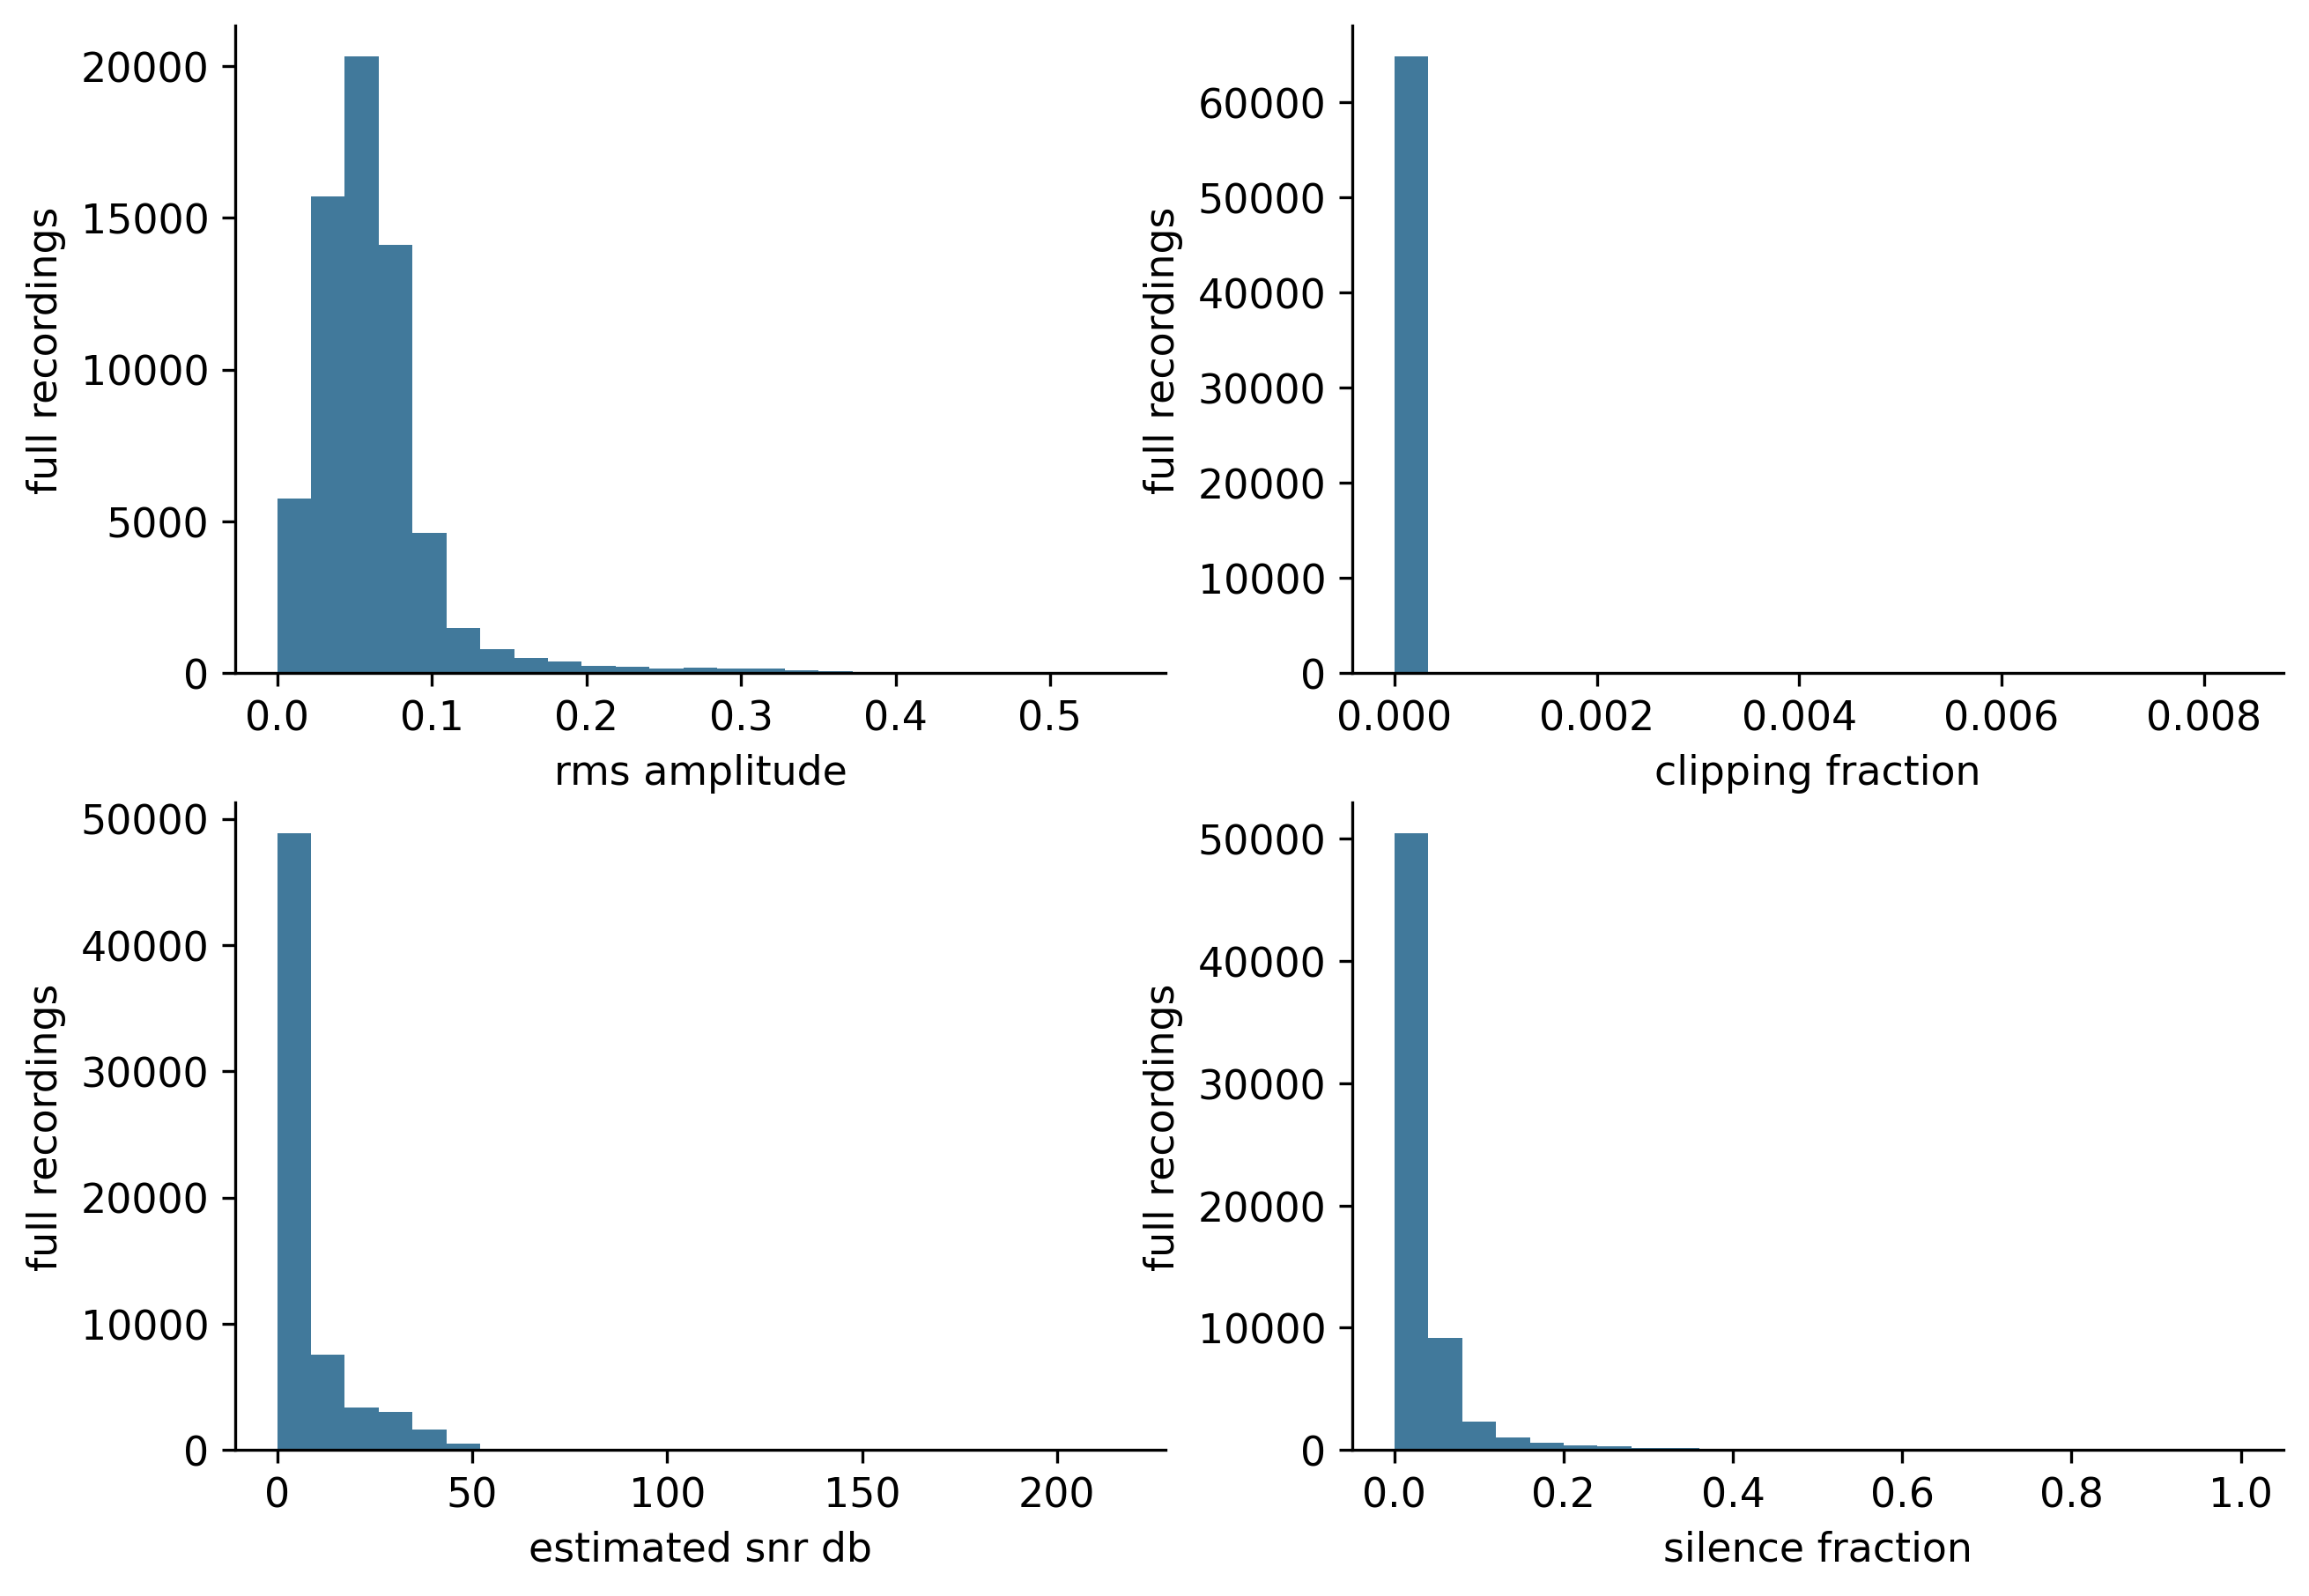

In [7]:
table('dataset_characterization/tables/quality_by_diagnosis.csv')
table('dataset_characterization/tables/qc_threshold_sensitivity.csv')
figure('dataset_characterization/figures/qc_distributions.png')

# Extracted acoustic measurements

The extractor uses mono 16-kHz decoded audio and emits 184 core feature columns,
plus interval information, processing status and optional pilot sensitivity
measurements. Measurements are recording-level. Undefined values remain missing;
these columns are not clinically validated diagnostic thresholds.

| Prefix | Count | Contents |
|---|---:|---|
| `praat_full__` | 22 | Whole-recording Praat measurements |
| `praat_stable__` | 22 | Same measurements on longest contiguous pitch-tracked interval >=0.5 s |
| `egemaps__` | 88 | Complete openSMILE eGeMAPSv02 Functionals |
| `spectral__` | 52 | Mean/SD of 26 spectral, energy and cepstral trajectories |

Each Praat set contains six F0 summaries (mean, median, SD, min, max, range),
F0 coefficient of variation, pitch-valid/unvoiced fractions, five jitter
measurements (local, absolute seconds, RAP, PPQ5, DDP), six shimmer measurements
(local, dB, APQ3, APQ5, APQ11, DDA), mean HNR in dB and the dimensionless ratio
`10**(-mean_hnr_db/10)`. Fractional perturbation values are not percentages.
The derived ratio is not an average of per-frame linear NHR values.
Praat uses autocorrelation pitch at 10-ms steps, 60–500 Hz, periodic
cross-correlation point processes, maximum period factor 1.3 and amplitude
factor 1.6. The selected interval does not certify physiological stability.
Interval start/end and total pitch-detected seconds are saved separately.

The 88 openSMILE columns include F0 and loudness distributions/slopes, spectral
flux, MFCCs 1–4, jitter, shimmer, HNR, H1–H2/H1–A3 harmonic differences,
F1–F3 frequencies/bandwidths/relative amplitudes, voiced/unvoiced spectral
balance/slopes, segment rates/durations and equivalent sound level. Native
standard column names are preserved. These include formant descriptors; a
separate Praat formant or CPP analysis is not implemented.

The spectral trajectories are centroid, bandwidth, rolloff, flatness,
zero-crossing rate, RMS, raw magnitude spectral flux, contrast indices 0–5,
and 13 MFCCs. Each exports mean and population SD. The STFT has 1,024 samples
and 160-sample hop (64/10 ms); MFCCs use 40 mel bands. `mfcc_1` through
`mfcc_13` number the returned coefficients starting at one. Contrast values
are in dB. RMS/flux depend on recording amplitude. ZCR uses a NumPy prefix-sum
implementation matching Librosa's edge centering, 1e-10 threshold,
positive-zero convention and no artificial crossing at frame starts.

Pilot-only sensitivity measurements repeat F0 mean, pitch-valid fraction,
local jitter and local shimmer for 50–400 Hz, 75–600 Hz, and removal of 250 ms
at each edge (12 additional values). The full run retains all 184 core columns
but omits these extra pilot checks. QC tables separately retain duration,
amplitude, energy/silence proxies, clipping, original codec/rate and hashes.

Implementation: `scripts/extract_acoustic_features.py`; settings:
`configs/mpower_preprocessing.yaml`; private per-field dictionary:
`$MPOWER_OUTPUT_ROOT/processed/feature_dictionary.csv`.

In [8]:
table('dataset_characterization/tables/feature_dictionary.csv')
table('dataset_characterization/tables/praat_opensmile_comparison.csv')

,feature,namespace,algorithm,units,interval,sample_rate_hz,validity,clinical_reference_range
0,praat_full__f0_mean_hz,praat_full,Praat via Parselmouth,Hz,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort
1,praat_full__f0_median_hz,praat_full,Praat via Parselmouth,Hz,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort
2,praat_full__f0_sd_hz,praat_full,Praat via Parselmouth,Hz,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort
3,praat_full__f0_min_hz,praat_full,Praat via Parselmouth,Hz,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort
4,praat_full__f0_max_hz,praat_full,Praat via Parselmouth,Hz,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort
5,praat_full__f0_range_hz,praat_full,Praat via Parselmouth,Hz,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort
6,praat_full__f0_cv,praat_full,Praat via Parselmouth,dimensionless,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort
7,praat_full__pitch_valid_fraction,praat_full,Praat via Parselmouth,dimensionless,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort
8,praat_full__unvoiced_fraction,praat_full,Praat via Parselmouth,dimensionless,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort
9,praat_full__jitter_local,praat_full,Praat via Parselmouth,dimensionless,full recording,16000,finite; undefined retained as missing; perturbation requires tracked periods,not established for this cohort


,praat,opensmile,paired,spearman,note
0,praat_full__f0_mean_hz,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,64936,0.906591,Definitions/units/intervals differ; correlation is not agreement in absolute units
1,praat_full__jitter_local,egemaps__jitterLocal_sma3nz_amean,64934,0.794650,Definitions/units/intervals differ; correlation is not agreement in absolute units
2,praat_full__shimmer_db,egemaps__shimmerLocaldB_sma3nz_amean,64930,0.859358,Definitions/units/intervals differ; correlation is not agreement in absolute units


,praat,opensmile,paired,spearman,note
0,praat_full__f0_mean_hz,egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,64936,0.906591,Definitions/units/intervals differ; correlation is not agreement in absolute units
1,praat_full__jitter_local,egemaps__jitterLocal_sma3nz_amean,64934,0.794650,Definitions/units/intervals differ; correlation is not agreement in absolute units
2,praat_full__shimmer_db,egemaps__shimmerLocaldB_sma3nz_amean,64930,0.859358,Definitions/units/intervals differ; correlation is not agreement in absolute units


## Full feature distributions, missingness and correlations

The 184-column summary includes finite counts, missingness, mean/SD and quantiles. Praat full-clip and pitch-selected-interval
measurements are different estimands. Whole-recording plots are descriptive; participant-median correlations reduce repeated-visit
dominance but remain observational and can reflect age, device and phonation duration. Formants in eGeMAPS are algorithmic
descriptors, not independently validated anatomical measurements. CPP and a separate Praat formant analysis were not implemented.

,feature,n,missing,mean,sd,min,max,q1,q5,q25,q50,q75,q95,q99,valid_fraction
0,praat_full__f0_mean_hz,64936,86,147.856489,53.502572,6.036084e+01,490.998585,77.785357,88.527577,110.052380,131.820079,175.618022,247.039581,336.680378,0.998677
1,praat_full__f0_median_hz,64936,86,149.014354,55.592070,5.998808e+01,498.354166,71.197722,85.396348,109.132507,133.137803,179.808689,250.257543,340.819697,0.998677
2,praat_full__f0_sd_hz,64936,86,14.338831,18.179642,2.923952e-02,203.012335,0.884612,1.172272,2.121751,5.175732,21.943751,49.955626,80.832404,0.998677
3,praat_full__f0_min_hz,64936,86,110.236591,52.934403,5.979690e+01,490.979907,59.827835,60.010276,70.290434,96.242195,129.063852,216.503227,304.052809,0.998677
4,praat_full__f0_max_hz,64936,86,198.735930,88.278447,6.195455e+01,499.995690,86.694358,99.887316,130.473207,178.721265,240.038898,387.014986,485.498305,0.998677
5,praat_full__f0_range_hz,64936,86,88.499339,92.315091,5.847905e-02,440.155173,5.785848,8.168250,17.869257,55.673468,128.114550,295.123916,401.791845,0.998677
6,praat_full__f0_cv,64936,86,0.099909,0.122656,6.628737e-05,0.968839,0.006834,0.009011,0.015509,0.036938,0.150850,0.349553,0.530458,0.998677
7,praat_full__pitch_valid_fraction,64973,49,0.915900,0.134903,0.000000e+00,1.000000,0.277230,0.653654,0.911824,0.958000,0.989000,1.000000,1.000000,0.999246
8,praat_full__unvoiced_fraction,64973,49,0.084100,0.134903,0.000000e+00,1.000000,0.000000,0.000000,0.011000,0.042000,0.088176,0.346346,0.722770,0.999246
9,praat_full__jitter_local,64934,88,0.008095,0.007272,3.441816e-04,0.134584,0.001806,0.002499,0.004072,0.005949,0.009494,0.020226,0.037218,0.998647


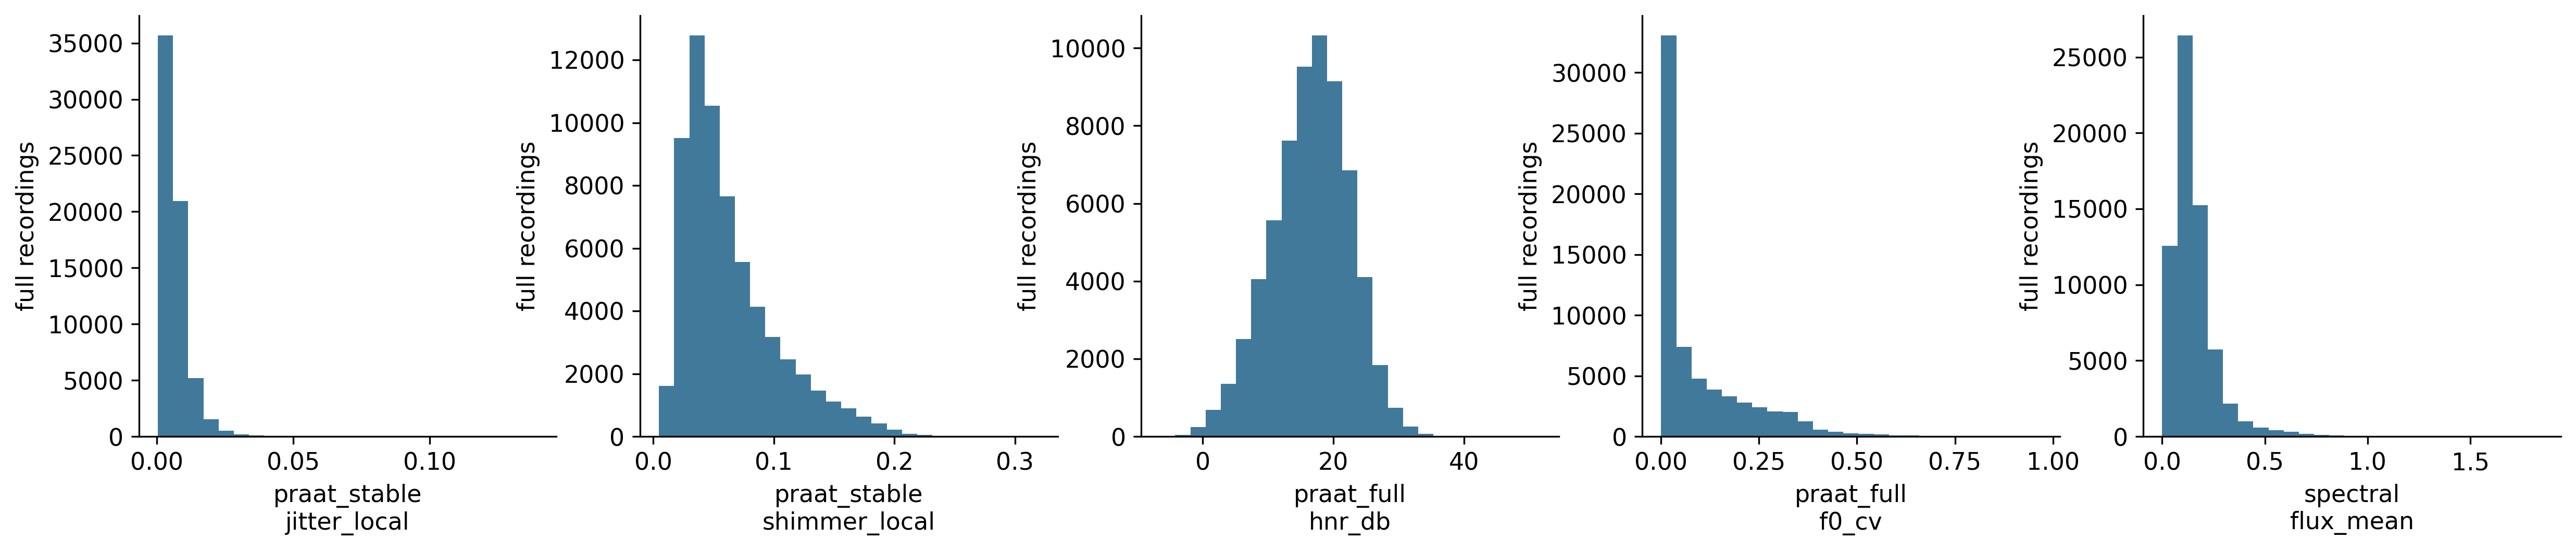

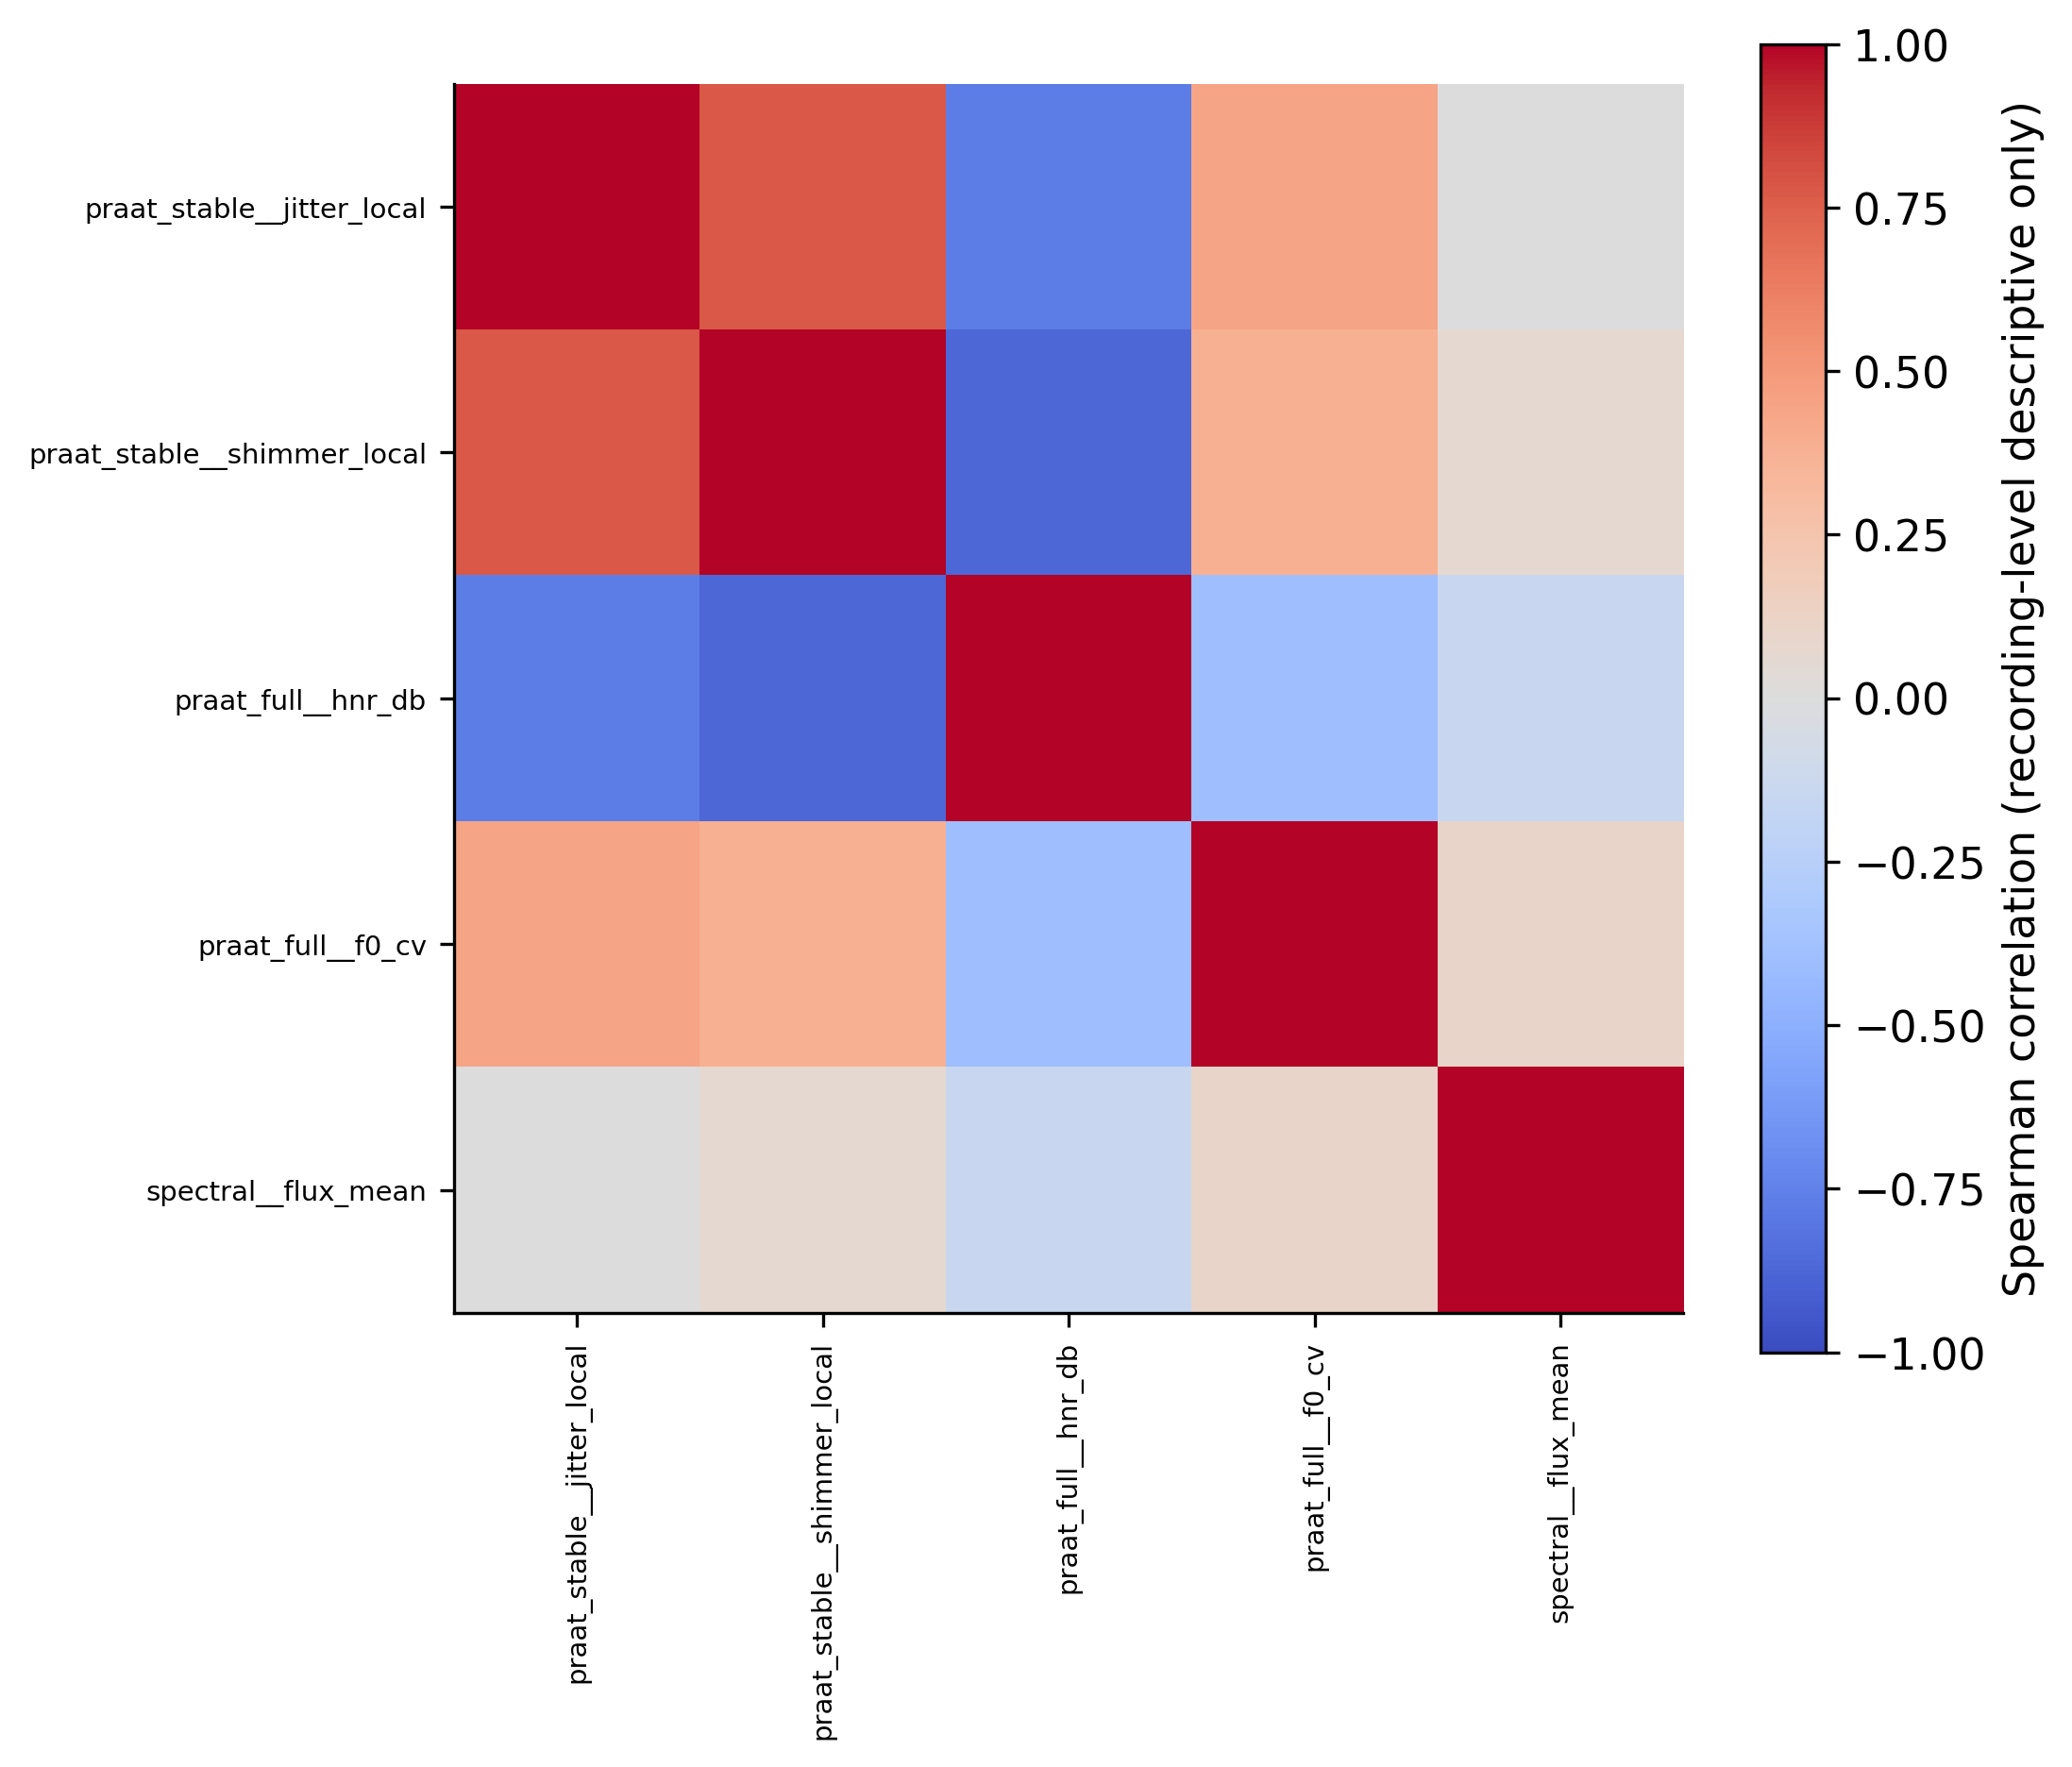

In [9]:
table('dataset_characterization/tables/full_feature_summary.csv')
figure('dataset_characterization/figures/acoustic_distributions.png')
figure('dataset_characterization/figures/selected_feature_correlations.png')

## Exploratory PD associations

Participant-median rank comparisons report rank-biserial effects and Benjamini–Hochberg FDR. Adjusted HC3 OLS summaries include
the stated age/gender/quality covariates. These are descriptive association screens, not proof of disease-specific mechanisms,
an externally validated biomarker or training-time feature selection. No feature is selected here using the sealed final-test endpoint.

In [10]:
table('dataset_characterization/tables/exploratory_pd_associations.csv')
table('dataset_characterization/tables/covariate_adjusted_pd_associations.csv')

,feature,pd_participants,control_participants,rank_biserial,p,fdr_bh
0,praat_full__f0_mean_hz,969,3880,0.217640,9.055535e-26,1.041387e-24
1,praat_full__f0_median_hz,969,3880,0.208451,8.962497e-24,8.245497e-23
2,praat_full__f0_sd_hz,969,3880,0.216453,1.657334e-25,1.793820e-24
3,praat_full__f0_min_hz,969,3880,0.014779,4.760247e-01,5.406701e-01
4,praat_full__f0_max_hz,969,3880,0.241854,1.963351e-31,1.204188e-29
5,praat_full__f0_range_hz,969,3880,0.221371,1.325412e-26,2.438758e-25
6,praat_full__f0_cv,969,3880,0.170961,1.658548e-16,9.844283e-16
7,praat_full__pitch_valid_fraction,970,3884,-0.111696,7.066100e-08,2.204763e-07
8,praat_full__unvoiced_fraction,970,3884,0.111694,7.069622e-08,2.204763e-07
9,praat_full__jitter_local,969,3880,0.090648,1.234381e-05,2.839076e-05


,feature,model,participants,pd_participants,pd_coefficient,ci_low,ci_high,p,fdr_bh
0,praat_full__f0_mean_hz,age_gender,4813,964,7.830156,4.888037,1.077228e+01,1.825827e-07,3.732802e-06
1,praat_full__f0_mean_hz,age_gender_quality,4813,964,8.612225,5.798431,1.142602e+01,1.986678e-09,4.061652e-08
2,praat_full__f0_median_hz,age_gender,4813,964,8.409167,5.374736,1.144360e+01,5.586635e-08,1.323065e-06
3,praat_full__f0_median_hz,age_gender_quality,4813,964,9.228425,6.332024,1.212483e+01,4.244000e-10,9.761201e-09
4,praat_full__f0_sd_hz,age_gender,4813,964,1.607287,0.203519,3.011054e+00,2.482464e-02,9.129013e-02
5,praat_full__f0_sd_hz,age_gender_quality,4813,964,1.123330,-0.237221,2.483881e+00,1.056127e-01,2.429091e-01
6,praat_full__f0_min_hz,age_gender,4813,964,1.080054,-2.372681,4.532789e+00,5.398112e-01,7.197483e-01
7,praat_full__f0_min_hz,age_gender_quality,4813,964,2.659116,-0.680099,5.998330e+00,1.185763e-01,2.660736e-01
8,praat_full__f0_max_hz,age_gender,4813,964,7.543752,1.139687,1.394782e+01,2.095661e-02,8.393629e-02
9,praat_full__f0_max_hz,age_gender_quality,4813,964,6.334959,0.220044,1.244987e+01,4.230646e-02,1.319388e-01


,feature,model,participants,pd_participants,pd_coefficient,ci_low,ci_high,p,fdr_bh
0,praat_full__f0_mean_hz,age_gender,4813,964,7.830156,4.888037,10.772275,1.825827e-07,3.732802e-06
1,praat_full__f0_mean_hz,age_gender_quality,4813,964,8.612225,5.798431,11.426020,1.986678e-09,4.061652e-08
2,praat_full__f0_median_hz,age_gender,4813,964,8.409167,5.374736,11.443598,5.586635e-08,1.323065e-06
3,praat_full__f0_median_hz,age_gender_quality,4813,964,9.228425,6.332024,12.124825,4.244000e-10,9.761201e-09
4,praat_full__f0_sd_hz,age_gender,4813,964,1.607287,0.203519,3.011054,2.482464e-02,9.129013e-02
...,...,...,...,...,...,...,...,...,...
363,spectral__mfcc_12_sd,age_gender_quality,4818,965,-0.017631,-0.100213,0.064952,6.756295e-01,8.232836e-01
364,spectral__mfcc_13_mean,age_gender,4818,965,-0.455547,-0.913304,0.002210,5.111626e-02,1.541868e-01
365,spectral__mfcc_13_mean,age_gender_quality,4818,965,-0.560254,-1.014499,-0.106009,1.563324e-02,6.689574e-02
366,spectral__mfcc_13_sd,age_gender,4818,965,0.028361,-0.052501,0.109223,4.918164e-01,6.855623e-01


## Cohort flow and split readiness

Legacy full extraction produced A: **62,123 recordings / 4,854 people**, B: **61,651 / 4,830**, C: **22,820 / 838**.
A is the labeled decoded cohort; B adds pitch/phonation criteria; C matches within reported gender and five-year age bins,
ages 50–80. These differ from the later technical development cohort, which excludes test people and requires at least two seconds.
Split tables below summarize the original frozen assignments without exposing identities or individual test outcomes.
Exact-duplicate-connected participants stay in one partition; near-duplicate/manual task-compliance review remains unresolved.

In [11]:
table('dataset_characterization/tables/qc_exclusion_flow.csv')
table('dataset_characterization/tables/cohort_demographic_balance.csv')
table('dataset_characterization/tables/age_gender_matching_flow.csv')
for name in ['A','B','C']:
    table(f'dataset_characterization/tables/cohort_{name}_splits.csv')
    table(f'dataset_characterization/tables/cohort_{name}_split_demographics.csv')
report('dataset_characterization/duplicate_summary.json')

,criterion,diagnosis,remaining_recordings,remaining_participants,scope
0,missing_identity,conflicting,678,102,full
1,missing_identity,control,22782,3890,full
2,missing_identity,pd,39388,970,full
3,missing_identity,unknown,2174,864,full
4,duplicate_source_identity,conflicting,678,102,full
5,duplicate_source_identity,control,22782,3890,full
6,duplicate_source_identity,pd,39388,970,full
7,duplicate_source_identity,unknown,2174,864,full
8,ambiguous_diagnosis,conflicting,0,0,full
9,ambiguous_diagnosis,control,22782,3890,full


,cohort,diagnosis,participants,age_mean,age_median,age_sd,age_missing,male,female,gender_missing
0,A,control,3884,32.707923,29.0,13.086849,22,3138,734,12
1,A,pd,970,60.336439,61.0,11.039714,4,630,338,2
2,B,control,3867,32.714769,29.0,13.083607,21,3125,730,12
3,B,pd,963,60.355579,61.0,11.027379,4,625,336,2
4,C,control,419,60.673031,60.0,7.341011,0,313,106,0
5,C,pd,419,60.811456,60.0,7.108204,0,313,106,0


,gender,age_bin_start,diagnosis,available_participants,retained_participants
0,Female,50,pd,35,34
1,Female,50,control,34,34
2,Female,55,pd,60,26
3,Female,55,control,26,26
4,Female,60,pd,69,19
5,Female,60,control,19,19
6,Female,65,pd,76,18
7,Female,65,control,18,18
8,Female,70,pd,39,9
9,Female,70,control,9,9


,split,diagnosis,recordings,participants
0,test,control,3520,583
1,test,pd,5473,145
2,train,control,15702,2718
3,train,pd,28007,679
4,val,control,3525,583
5,val,pd,5896,146


,split,diagnosis,participants,age_mean,age_median,male,female
0,test,control,583,32.310881,29.0,471,109
1,test,pd,145,59.944828,62.0,89,56
2,train,control,2718,32.909024,29.0,2191,520
3,train,pd,679,60.501479,61.0,452,226
4,val,control,583,32.165803,29.0,476,105
5,val,pd,146,59.958621,61.0,89,56


,split,diagnosis,recordings,participants
0,test,control,3498,580
1,test,pd,5453,145
2,train,control,15599,2707
3,train,pd,27768,673
4,val,control,3497,580
5,val,pd,5836,145


,split,diagnosis,participants,age_mean,age_median,male,female
0,test,control,580,32.347222,29.0,468,109
1,test,pd,145,59.944828,62.0,89,56
2,train,control,2707,32.900148,29.0,2184,516
3,train,pd,673,60.540299,61.0,447,225
4,val,control,580,32.215278,29.0,473,105
5,val,pd,145,59.909722,61.0,89,55


,split,diagnosis,recordings,participants
0,test,control,1141,63
1,test,pd,1599,57
2,train,control,4225,302
3,train,pd,11994,296
4,val,control,1110,54
5,val,pd,2751,66


,split,diagnosis,participants,age_mean,age_median,male,female
0,test,control,63,58.714286,57.0,45,18
1,test,pd,57,61.421053,60.0,39,18
2,train,control,302,61.139073,60.0,225,77
3,train,pd,296,60.875000,60.0,226,70
4,val,control,54,60.351852,59.5,43,11
5,val,pd,66,60.000000,59.0,48,18


```json
{
  "file_sha256": {
    "groups": 27,
    "recordings": 74,
    "cross_participant_groups": 1
  },
  "native_pcm_sha256": {
    "groups": 26,
    "recordings": 56,
    "cross_participant_groups": 0
  },
  "normalized_pcm_sha256": {
    "groups": 26,
    "recordings": 56,
    "cross_participant_groups": 0
  },
  "near_duplicates": "Not yet validated: no claim of exhaustive near-duplicate detection; release blocked pending review."
}
```

## Extraction failure audit and exact preprocessing methods

The following source-audited methods and failure report document implementation, diagnosis linkage and what was repaired.
Historical pilot counts are explicitly labeled and must not replace the full-scope results above.

# Reproducible Phase 1 execution

**Completed full-scope update (November16,2026):** 64,973/65,022 source recordings
decoded/extracted; the remaining49 match malformed/empty Synapse source objects.
Current distributions and full-scope associations are in the
[executed dataset report](01_mPower_Dataset_Characterization.ipynb).
Pilot/job-start notes below are historical. The original private notebook
template remains output-free; the two public report notebooks contain reviewed
aggregate outputs only.

Read `AGENTS.md`, `data_layout.md` and `configs/mpower_preprocessing.yaml` first. No raw files are changed and no additional datasets are downloaded. Participant-bearing manifests, schemas, caches, figures and executed notebooks go to approved storage outside Git. Source notebook outputs are clear.

Use Python 3.12 (tested), not the current Python 3.15 `pd_env` interpreter. Create a separate compatible environment and install `requirements-preprocessing.txt`. Direct dependencies are pinned; the Slurm job records the complete installed environment and FFmpeg version. A bundled imageio FFmpeg executable is a fallback when system FFmpeg is absent. A pre-staged environment archive may be unpacked to compute-node temporary storage with `MPOWER_ENV_ARCHIVE`; it must be compatible with compute-node OS and the base interpreter must be accessible.

```bash
export MPOWER_DATA_ROOT=/approved/raw/root
export MPOWER_OUTPUT_ROOT=/approved/derived/mpower_phase1
export MPOWER_PYTHON=/approved/environment/bin/python
mkdir -p logs
sbatch --export=ALL scripts/preprocess_mpower.slurm
```

All large inventories, real-audio pilot extraction, reporting and full runs must execute through Slurm. The default is a 120-recording pilot, 2 CPUs, 12 GB RAM, 12-hour limit. Check pilot extraction statuses and sensitivity analyses before submitting `MPOWER_SCOPE=full`; full extraction must not be launched locally. The batch pipeline inventories all raw tables, audits/canonicalizes metadata, extracts audio/QC/features, builds cohorts, attempts splits, creates tables/figures/report and executes the notebook to private storage. The scheduler resource request may need adjustment after pilot timing. Do not automatically scale an unreviewed pilot.

```bash
# After pilot review only:
export MPOWER_SCOPE=full
# Reuse an audited unchanged metadata census only after verifying inputs:
export MPOWER_SKIP_AUDIT=1
sbatch --export=ALL scripts/preprocess_mpower.slurm
```

Intermediate outputs are atomic. Each recording has a cache key including audio path, size, modification time, config hash, extraction/QC/common-code hashes and library versions. Successful results are reused; errors/partial extraction retry. Raw-file stat keys are not a substitute for cryptographic raw integrity checks; file hashes are also saved. Work submission and decoded audio memory are bounded; pilot checkpoints update every worker batch, while full checkpoints update initially, approximately every 1,000 results and at completion. Successful per-recording caches are atomic between checkpoints. Spawned workers recycle after 250 tasks. If a native worker exits abruptly, successful results are retained and unresolved batch rows retry in isolated processes; repeat native failures receive explicit worker-error status. Errors do not abort the recording loop, though dependency/configuration errors should be fixed before rerunning. Configured maximum duration is 180 s: longer files are flagged for review rather than silently truncated. Source recordings remain unchanged.

Praat uses autocorrelation pitch 60–500 Hz, 10-ms steps, periodic-cc point processes, period factor 1.3 and amplitude factor 1.6. Local/absolute/RAP/PPQ5/DDP jitter, local/dB/APQ3/APQ5/APQ11/DDA shimmer, F0 summaries and HNR are extracted. NHR derived from mean HNR is explicitly named and is not the mean linear NHR. Perturbation values are fractions, except absolute jitter (seconds) and shimmer dB. Full-recording and longest contiguous pitched interval >=0.5 s measurements are separated. The interval selection does not minimize jitter or shimmer and does not certify stationarity. Undefined values remain missing. Pilot repeats pitch ranges 50–400 / 75–600 Hz and removes 250 ms from both edges for sensitivity.

openSMILE eGeMAPSv02 provides 88 full-recording functionals with original names,
including its native F1–F3 frequency/bandwidth/relative-amplitude descriptors.
The spectral extractor provides STFT1024-point/160-sample-hop centroid,
bandwidth, rolloff, flatness, six contrast indices0–5, RMS, ZCR, raw FFT flux,
and13 MFCC mean/SD values from40 mel bands. Flux is not amplitude-normalized.
A separate Praat formant analysis, CPP, LLD exports, DDK and language features
are not implemented. No transformer/model training occurs in this extraction stage.

Participant-level median aggregation avoids counting repeated recordings as independent in optional exploratory rank comparisons; rank-biserial effects and BH FDR are implemented. After authorized demographics linkage, `demographic_eda.py` computes baseline-age/reported-gender distributions, SMD, PD-stratified duration/QC/frequency summaries, other available covariates, and participant-median OLS with HC3 errors adjusted for age/gender and additionally median recording quality. BH FDR is applied separately to the two adjustment specifications. These are exploratory pilot models, not clinical validation. Cohort C matches equal participant counts within 5-year age bins and gender. Baseline demographic covariates are not time-updated clinical measurements. Separate descriptive recording-level correlations must not be interpreted as participant-independent inference.

Validation: `python -m pytest -q tests` uses synthetic metadata, periodic signals and silence to check source-row retention, missing-label handling, longitudinal label conflicts, join/config integrity, corrupt-file error recording, expected F0, all 88 eGeMAPS features, undefined perturbation values, deterministic extraction and duplicate-linked participant split isolation. No synthetic participant records are presented as observed data.

Algorithm references: [Praat jitter definitions](https://www.fon.hum.uva.nl/praat/manual/Voice_2__Jitter.html), [Praat automated voice analysis](https://www.fon.hum.uva.nl/praat/manual/Voice_6__Automating_voice_analysis_with_a_script.html), [Parselmouth API](https://parselmouth.readthedocs.io/en/stable/api_reference.html), [openSMILE usage](https://audeering.github.io/opensmile-python/usage.html), [librosa documentation](https://librosa.org/doc/0.10.2/).

The generated final report includes an executed-scope manuscript Methods draft and answers each requested analysis category with computed results or an explicit blocker. It must be revised after metadata linkage and full processing; it is not a completed PD biomarker manuscript.

The authorized demographics-only downloader and its Slurm wrapper are `scripts/download_mpower_demographics.py` and `.slurm`. They use the existing credential file without logging it, export only syn5511429, download no audio, and refuse to overwrite an existing snapshot. `scripts/linked_pilot_mpower.slurm` preserves the original voice-only pilot, reuses the audited voice census, links demographics, runs a diagnosis-stratified pilot and regenerates reports. The download does not authorize downloading UPDRS/PDQ-8 surveys or any other table.

## Executed jobs in this session

- `27497408`: voice-only census and 120-recording pilot, completed; archived under `archive/voice_only_pilot/`.
- `27497846`: authorized metadata-only demographics export, completed.
- `27497956`: audited demographic linkage and diagnosis-stratified 120-recording pilot, completed; archived before full processing under `archive/linked_pilot/`.
- `27498284`: initial full run failed when a native worker exited abruptly; no full result is claimed. Slurm peak RSS was about 2.1 GB, without an OOM state.
- `27498642`: full run resubmitted with spawned workers, periodic worker recycling, isolated retries and native crash tracing; 16 CPUs / 48 GB / 24-hour limit. Submission is not evidence of successful full completion. Check scheduler state and job logs before citing full results.

Observed linked census: 970 participants report professional PD diagnosis, 3,992 report no diagnosis and 864 are unknown (including unmatched surveys). A conservative contradiction audit quarantines 102 of the self-reported controls, leaving 3,890 primary controls. Source labels remain intact. Primary PD/control age mean difference is 27.64 years and standardized difference is 2.28, so unadjusted disease comparisons are strongly confounded.

The linked pilot decoded/extracted 120/120 recordings; stable-interval jitter was defined for 117/120. Five repeat extractions reproduced. Pilot cohorts A/B/C contain 56/55/12 participants respectively, each with one selected recording; these are coverage-sample counts, not full-cohort yields. The pilot A partitions have 40 train, 8 validation and 8 test participants/recordings. No pilot adjusted acoustic comparison passed BH FDR <0.05 among 368 feature/model comparisons; this is not evidence of equivalence or absence of a disease signal. The full job must generate its own denominators and inferential summaries.

Final synthetic verification: 9 tests pass, including deliberately terminated native-worker containment followed by successful task execution. This does not establish that every real recording is decodable; use the per-recording full-run statuses.

# Failed-recording audit — November 14, 2026

The full preprocessing job 27554188 completed successfully in 3:22:34 with
64,973 successful decodes/extractions and 49 failed recordings out of 65,022.
All downstream cohorts, tables, report and notebook were generated. The notebook
now uses full audio scope; all 14 code cells executed without saved errors.
These 49 errors are distinct from the earlier native-worker crash incident.

## Findings

All 49 local files match the content size AND MD5 checksum returned by Synapse
for their authorized Voice Activity table file handles. Metadata were checked
through the existing authenticated file-handle service; no audio was downloaded
and no credentials or signed URLs were saved. Thus the local copies match the
source objects. Re-downloading those same objects is not a repair.

| Count | File structure | FFmpeg diagnostic |
|---:|---|---|
| 18 | Exactly 28 bytes: MP4 `ftyp` box only, with no movie metadata or audio payload | `moov atom not found` |
| 1 | 16,392 bytes: `ftyp` followed by an invalid/unrecognized zero-type box; no `moov` or `mdat` | `moov atom not found` |
| 30 | MP4/ALAC containers with only 8 or 16 bytes of `mdat` payload; headers advertise approximately 0.09 or 0.19 seconds | `invalid samples per frame: 0`, decode error rate 1 |

The damaged ALAC headers do not establish a valid recording duration. These
structures are consistent with empty/incomplete source captures; the exact
upstream recording or upload failure cannot be determined from the files.

A four-core read-only Slurm audit (job 27562918, COMPLETED, exit 0, six seconds)
replayed decoding for all 49 files and tested FFmpeg error-tolerant decoding
(`-err_detect ignore_err -fflags +discardcorrupt`). Both modes produced **zero
samples for every file**. No partial waveform is available to run through
Praat, openSMILE or spectral extraction. No source files or completed canonical
outputs were changed. The 49 recordings should retain explicit failure status;
missing acoustic values must not be replaced with zeros or synthetic audio.

The 49 failed recordings have 32 distinct SHA256 hashes. Some empty/malformed
objects therefore have identical bytes; this is not evidence of shared valid
voice recordings. Do not interpret these failed-file hashes as vocal similarity.

## Evidence and reproducibility

The versioned read-only diagnostic is `scripts/audit_audio_failures.py`:

```bash
# Run through a Slurm allocation, with approved paths configured.
python scripts/audit_audio_failures.py --root "$MPOWER_OUTPUT_ROOT" --workers 4
```

It audits failed entries from the full QC table and writes a timestamped private
directory under `eda/diagnostics/`. Evidence from this run is in:

```text
pd_data/mpower_phase1/eda/diagnostics/failed_audio_audit_20261114T065949Z/
  failures.csv                        per-recording file structure/decode summary
  <recording_id>.json                  MP4 box layout and complete decoder evidence
  summary.json                        aggregate decoder results
  source_checksum_comparison.json     per-file source/local checksum and size checks
  source_checksum_summary.json        aggregate source-match results
  verify_remote.py                    private metadata-verification script
```

Participant-bearing identifiers and paths stay in that private directory. The
three structural diagnostic tests passed, covering header-only files, payload
byte counts, zero/extended-size boxes and truncated boxes. No complete extraction
rerun is needed because none of the source files or extraction values changed.

Recommendation: retain these failures and their reasons in the audit trail.
Recovery would require a different valid upstream recording/object from the
data provider; changing decoder settings cannot recreate absent audio samples.
No provider contact or additional dataset download was performed.

## Exact extraction configuration

```yaml
# Paths are resolved from environment; derived participant data stay outside Git.
data_root_env: MPOWER_DATA_ROOT
output_root_env: MPOWER_OUTPUT_ROOT
metadata: voice_activity/Voice_Activity.csv
demographics: demographics/Demographics.csv
columns:
  participant: healthCode
  recording: recordId
  timestamp: createdOn
  audio: audio_path
  handle: audio_audio.m4a
  medication: medTimepoint
  # Unavailable in the inspected Voice Activity table. Configure only after auditing.
  diagnosis: null
  age: null
  sex: null
# Explicit value mappings; medication is never used as a diagnosis proxy.
diagnosis_values:
  pd: ['true']
  control: ['false']
seed: 20261112
pilot_size: 120
workers: 2
sample_rate: 16000
max_decode_seconds: 180
pitch:
  floor: 60
  ceiling: 500
  max_period_factor: 1.3
  max_amplitude_factor: 1.6
  sensitivity_ranges: [[50, 400], [75, 600]]
qc:
  frame_ms: 30
  hop_ms: 10
  near_silence_rms: 0.0001
  low_amplitude_rms: 0.001
  energy_db_below_peak: 35
  min_duration_s: 2
  min_voiced_s: 2
  clipping_amplitude: 0.999
  clipping_fraction: 0.01
  estimated_snr_db: 10
  min_pitch_fraction: 0.5
split_fractions: [0.70, 0.15, 0.15]
age_restriction: [50, 80]

```

## Limits and lab handoff

The primary analysis is observational, self-selected and demographically imbalanced; it does not establish diagnosis in a clinical setting.
Near-duplicate review, manual phonation compliance, age/device common-support evaluation and independent final testing remain necessary.
Real recordings stay in approved storage; `samples/mpower_100/README.md` explains the prepared private training sample and access procedure.

Dataset reference: Bot et al., *The mPower study, Parkinson disease mobile data collected using ResearchKit*, Scientific Data (2016),
[doi:10.1038/sdata.2016.11](https://doi.org/10.1038/sdata.2016.11).
Acoustic descriptor reference: Eyben et al., *The Geneva Minimalistic Acoustic Parameter Set (GeMAPS) for Voice Research and Affective Computing*,
[doi:10.1109/TAFFC.2015.2457417](https://doi.org/10.1109/TAFFC.2015.2457417).